# Microscopy Image Analysis Basics

**A hands-on introduction using Python, NumPy, Matplotlib, SciPy, and scikit-image**

This notebook introduces the core ideas behind quantitative microscopy image analysis. The examples are deliberately small and synthetic so that you can see exactly what the computer is doing.

## Learning goals

By the end of this notebook, you should be able to:

- Explain that a digital image is an array of numerical pixel values.
- Distinguish image **data** from image **visualization**.
- Work with images that contain multiple channels, Z planes, and time points.
- Explain bit depth, dynamic range, pixel size, and spatial resolution.
- Apply basic image filters such as Gaussian blur and edge detection.
- Convert an intensity image into a binary mask using thresholding.
- Explain segmentation and simple morphological cleanup.
- Identify connected components and measure objects.
- Explain the purpose of image registration and perform a simple translation registration.
- Connect image processing operations to a reproducible quantitative workflow.

> **Teaching principle:** A microscopy image is data first and a picture second.

## 0. Setup

The notebook uses common scientific-Python packages. If they are missing on your system, install them with:

```bash
pip install numpy scipy matplotlib scikit-image pandas tifffile
```

`ipywidgets` is used in the real-world example to create slider widgets.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage as ndi

from skimage import filters, feature, measure, morphology, registration, exposure
import tifffile

np.random.seed(7)

plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["font.size"] = 12

## 1. A digital image is an array of numbers

A grayscale image can be represented as a 2-D array. Each array element corresponds to one pixel.

In Python, the usual indexing order is:

```text
image[y, x]
```

not `image[x, y]`.

In [2]:
img = np.zeros((12, 16), dtype=np.uint8)

img[2:6, 3:7] = 80
img[7:11, 9:14] = 180
img[4:8, 12:14] = 255

print("Shape:", img.shape)
print("Data type:", img.dtype)
print("Minimum:", img.min())
print("Maximum:", img.max())

img

Shape: (12, 16)
Data type: uint8
Minimum: 0
Maximum: 255


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0],
       [  0,   0,   0,  80,  80,  80,  80,   0,   0,   0,   0,   0,   0,
          0,   0,   0],
       [  0,   0,   0,  80,  80,  80,  80,   0,   0,   0,   0,   0,   0,
          0,   0,   0],
       [  0,   0,   0,  80,  80,  80,  80,   0,   0,   0,   0,   0, 255,
        255,   0,   0],
       [  0,   0,   0,  80,  80,  80,  80,   0,   0,   0,   0,   0, 255,
        255,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 255,
        255,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0, 180, 180, 180, 255,
        255,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0, 180, 180, 180, 180,
        180,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0, 180, 180, 180, 180,
        180,   0,   0],
       [  0,   0,   0,   0,   

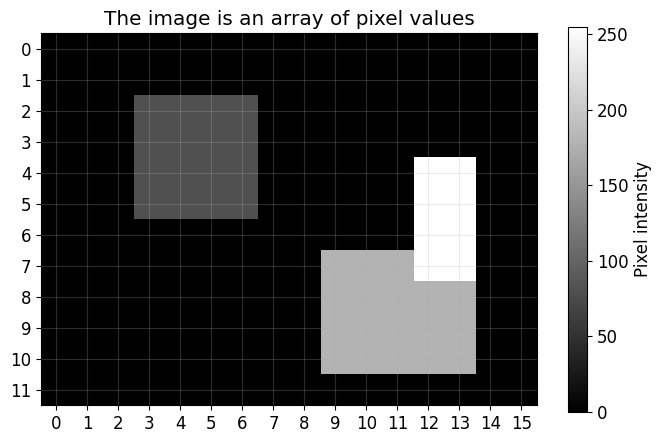

In [3]:
plt.figure(figsize=(8, 5))
plt.imshow(img, cmap="gray", interpolation="nearest")
plt.colorbar(label="Pixel intensity")
plt.xticks(range(img.shape[1]))
plt.yticks(range(img.shape[0]))
plt.grid(alpha=0.25)
plt.title("The image is an array of pixel values")
plt.show()

In [4]:
print("Pixel at y=3, x=4:", img[3, 4])
print("Pixel at y=8, x=10:", img[8, 10])
print("Pixel at y=0, x=0:", img[0, 0])

Pixel at y=3, x=4: 80
Pixel at y=8, x=10: 180
Pixel at y=0, x=0: 0


### Try it yourself

        1. Print the value of the pixel at `y=5, x=13`.
2. Make a copy of `img`, change one background pixel to 255, and display it.

In [5]:
# 1.
# YOUR CODE HERE

# 2.
# YOUR CODE HERE

## 2. Image dimensions: X, Y, Z, channel, and time

Microscopy datasets often contain more than two dimensions. A common conceptual ordering is:

```text
T, C, Z, Y, X
```

where:

- **T** = time
- **C** = channel
- **Z** = optical section / depth
- **Y, X** = image plane

File formats and libraries may store dimensions in different orders, so always inspect metadata and array shape.

In [6]:
# Create a tiny 5-D example: T, C, Z, Y, X
demo_5d = np.zeros((4, 3, 5, 64, 80), dtype=np.uint16)

print("Shape:", demo_5d.shape)
print("T =", demo_5d.shape[0])
print("C =", demo_5d.shape[1])
print("Z =", demo_5d.shape[2])
print("Y =", demo_5d.shape[3])
print("X =", demo_5d.shape[4])

Shape: (4, 3, 5, 64, 80)
T = 4
C = 3
Z = 5
Y = 64
X = 80


Selecting one 2-D plane means choosing one time point, one channel, and one Z plane:

In [7]:
plane = demo_5d[2, 1, 3]

print("Selected plane shape:", plane.shape)

Selected plane shape: (64, 80)


### Try it yourself

Extract time point 1, channel 2, Z plane 4 from `demo_5d`. What shape does the result have?

In [8]:
# YOUR CODE HERE

## 3. Channels are data; colors are display choices

Fluorescence channels are independent intensity arrays. A channel is not inherently “green” or “magenta.” A lookup table, or LUT, determines how numerical values are displayed.

In [9]:
y, x = np.mgrid[:256, :256]

ch0 = np.exp(-((x - 85)**2 + (y - 130)**2) / (2 * 28**2))
ch1 = np.exp(-((x - 165)**2 + (y - 115)**2) / (2 * 34**2))

channels = np.stack([ch0, ch1])

print("Channels array shape:", channels.shape)

Channels array shape: (2, 256, 256)


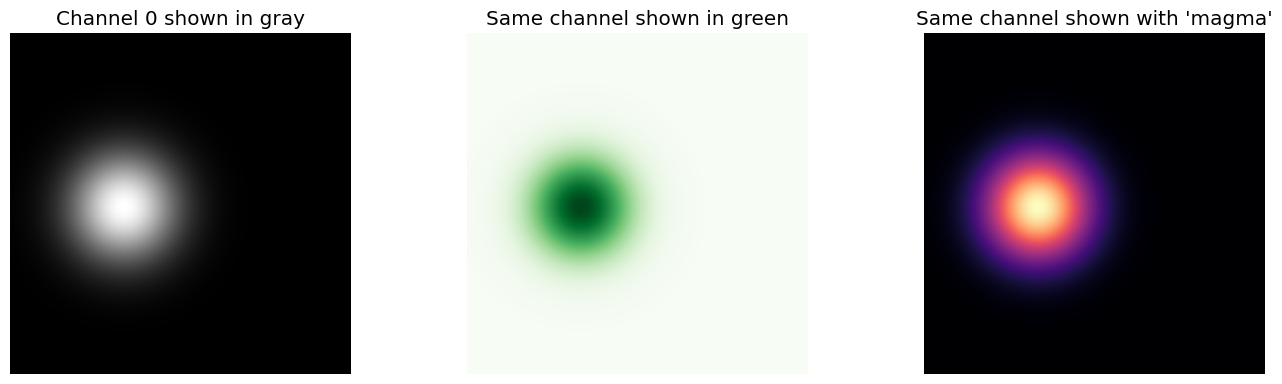

Underlying value at [130, 85]: 1.0


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(channels[0], cmap="gray")
axes[0].set_title("Channel 0 shown in gray")

axes[1].imshow(channels[0], cmap="Greens")
axes[1].set_title("Same channel shown in green")

axes[2].imshow(channels[0], cmap="magma")
axes[2].set_title("Same channel shown with 'magma'")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Underlying value at [130, 85]:", channels[0, 130, 85])

The three panels above contain the **same numerical data**. Only the mapping from intensity to screen color changed.

Compare that with a real processing operation:

In [11]:
blurred_ch0 = filters.gaussian(channels[0], sigma=5)

print("Original pixel:", channels[0, 130, 85])
print("Blurred pixel :", blurred_ch0[130, 85])

Original pixel: 1.0
Blurred pixel : 0.9691168814242703


**Key distinction**

- Changing a LUT: visualization changes, underlying pixel values do not.
- Filtering, arithmetic, thresholding, resampling: the underlying data change.

## 4. Display range can strongly change appearance

A LUT is not the only display choice. The displayed minimum and maximum also matter.

Here, the data remain unchanged, but the contrast changes:

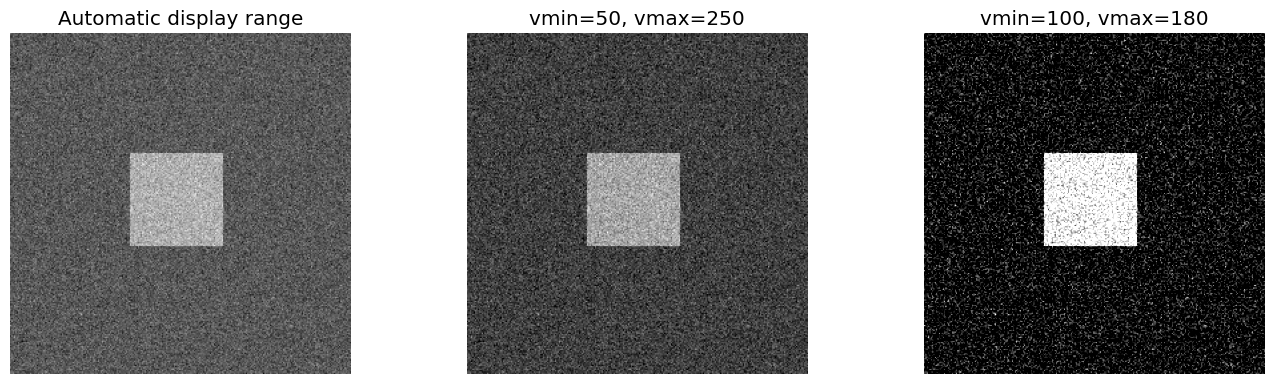

Data min/max: 17.71008343025686 254.55382937475153


In [12]:
noisy = 100 + 20 * np.random.randn(256, 256)
noisy[90:160, 90:160] += 80

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(noisy, cmap="gray")
axes[0].set_title("Automatic display range")

axes[1].imshow(noisy, cmap="gray", vmin=50, vmax=250)
axes[1].set_title("vmin=50, vmax=250")

axes[2].imshow(noisy, cmap="gray", vmin=100, vmax=180)
axes[2].set_title("vmin=100, vmax=180")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Data min/max:", noisy.min(), noisy.max())

This is a major microscopy lesson: **an image can look dramatically different without the data changing at all**.

## 5. Bit depth and dynamic range

Bit depth determines how many integer values are available:

- 4-bit: 16 possible values
- 8-bit: 256 possible values
- 12-bit: 4096 possible values
- 16-bit: 65536 possible values

A larger storage bit depth does not guarantee that the detector used the full available range.

In [13]:
gradient = np.tile(np.linspace(0, 1, 512), (100, 1))

img_4bit = np.round(gradient * 15).astype(np.uint8)
img_8bit = np.round(gradient * 255).astype(np.uint8)
img_16bit = np.round(gradient * 65535).astype(np.uint16)

print("Unique values in 4-bit simulation :", len(np.unique(img_4bit)))
print("Unique values in 8-bit image      :", len(np.unique(img_8bit)))
print("Unique values in 16-bit image     :", len(np.unique(img_16bit)))

Unique values in 4-bit simulation : 16
Unique values in 8-bit image      : 256
Unique values in 16-bit image     : 512


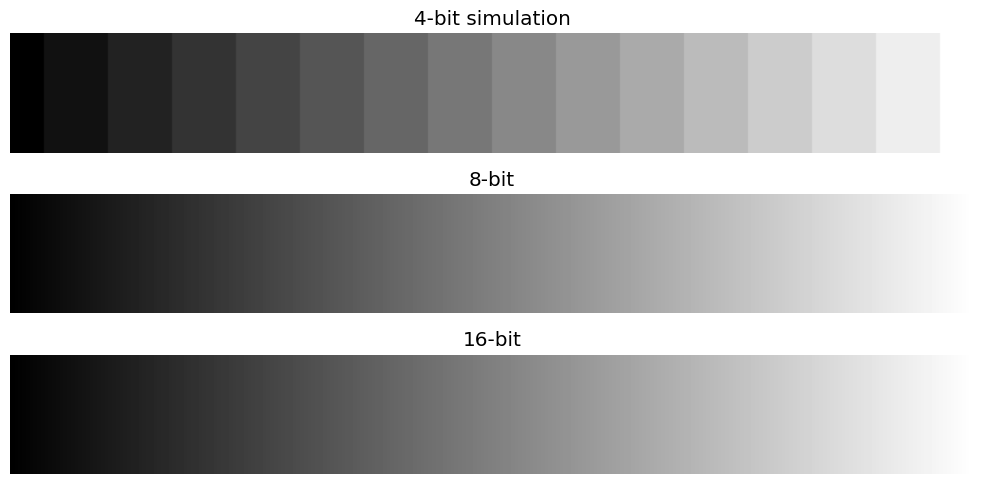

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(10, 5))

axes[0].imshow(img_4bit, cmap="gray", aspect="auto")
axes[0].set_title("4-bit simulation")

axes[1].imshow(img_8bit, cmap="gray", aspect="auto")
axes[1].set_title("8-bit")

axes[2].imshow(img_16bit, cmap="gray", aspect="auto")
axes[2].set_title("16-bit")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Histograms describe intensity distributions

A histogram counts how many pixels fall into each intensity range.

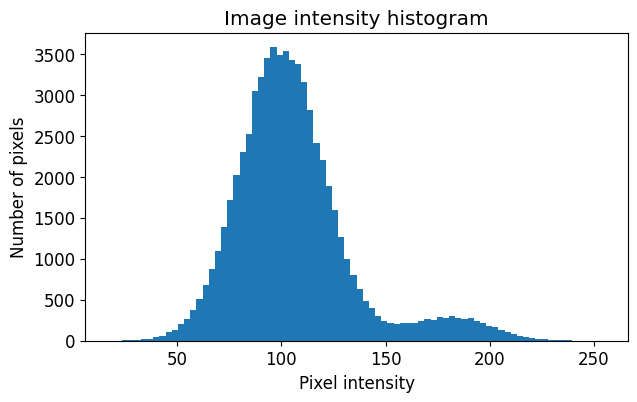

In [15]:
plt.figure(figsize=(7, 4))
plt.hist(noisy.ravel(), bins=80)
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")
plt.title("Image intensity histogram")
plt.show()

Histograms are useful for:

- checking background and signal distributions,
- seeing clipping or saturation,
- choosing display ranges,
- understanding thresholding.

## 7. Pixel size is not the same as spatial resolution

Suppose the camera sampling is:

```text
0.65 micrometers per pixel
```

Then a 100-pixel distance corresponds to:

In [16]:
pixel_size_um = 0.65
distance_px = 100

distance_um = distance_px * pixel_size_um

print(f"{distance_px} pixels = {distance_um:.1f} micrometers")

100 pixels = 65.0 micrometers


**Sampling** tells us how physical distance maps onto pixels.

**Optical spatial resolution** tells us how well the microscope can distinguish nearby structures.

An image sampled at 0.1 µm/pixel does **not** necessarily have 0.1 µm optical resolution. Oversampling creates more pixels without necessarily creating more biological detail.

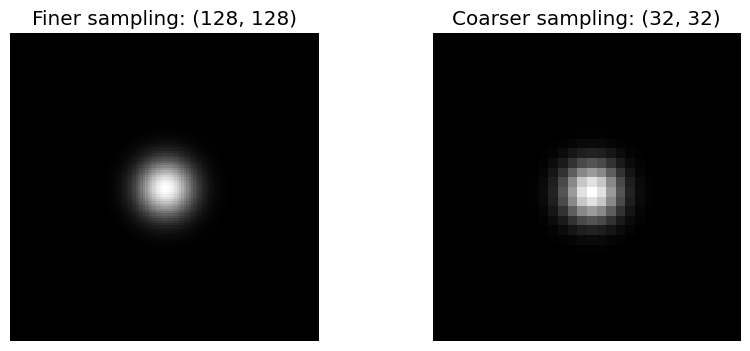

In [17]:
# Demonstrate how the same object looks under different sampling.
yy, xx = np.mgrid[-64:64, -64:64]
continuous_like = np.exp(-(xx**2 + yy**2) / (2 * 8**2))

fine = continuous_like
coarse = continuous_like[::4, ::4]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(fine, cmap="gray", interpolation="nearest")
axes[0].set_title(f"Finer sampling: {fine.shape}")

axes[1].imshow(coarse, cmap="gray", interpolation="nearest")
axes[1].set_title(f"Coarser sampling: {coarse.shape}")

for ax in axes:
    ax.axis("off")

plt.show()

## 8. Create a synthetic microscopy image

From here onward, we will use a small “cell-like” synthetic fluorescence image. Because we generated it ourselves, we know what structures should exist.

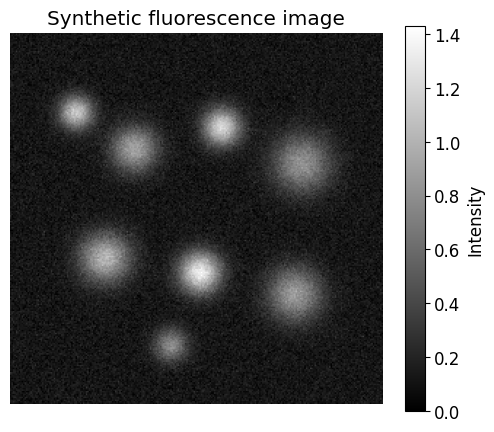

In [18]:
def add_gaussian_spot(image, x0, y0, amplitude, sigma):
    yy, xx = np.mgrid[:image.shape[0], :image.shape[1]]
    image += amplitude * np.exp(
        -((xx - x0)**2 + (yy - y0)**2) / (2 * sigma**2)
    )

microscopy = np.zeros((256, 256), dtype=np.float32)

spots = [
    (45, 55, 1.0, 8),
    (85, 80, 0.8, 11),
    (145, 65, 1.1, 9),
    (200, 90, 0.7, 14),
    (65, 155, 0.9, 12),
    (130, 165, 1.2, 10),
    (195, 180, 0.75, 13),
    (110, 215, 0.65, 8),
]

for x0, y0, amp, sigma in spots:
    add_gaussian_spot(microscopy, x0, y0, amp, sigma)

microscopy += 0.12
microscopy += np.random.normal(0, 0.055, microscopy.shape)
microscopy = np.clip(microscopy, 0, None)

plt.imshow(microscopy, cmap="gray")
plt.colorbar(label="Intensity")
plt.title("Synthetic fluorescence image")
plt.axis("off")
plt.show()

## 9. Filtering

Filters replace each pixel using information from its neighborhood.

### Gaussian blur

Gaussian filtering suppresses high-frequency noise but also smooths object boundaries.

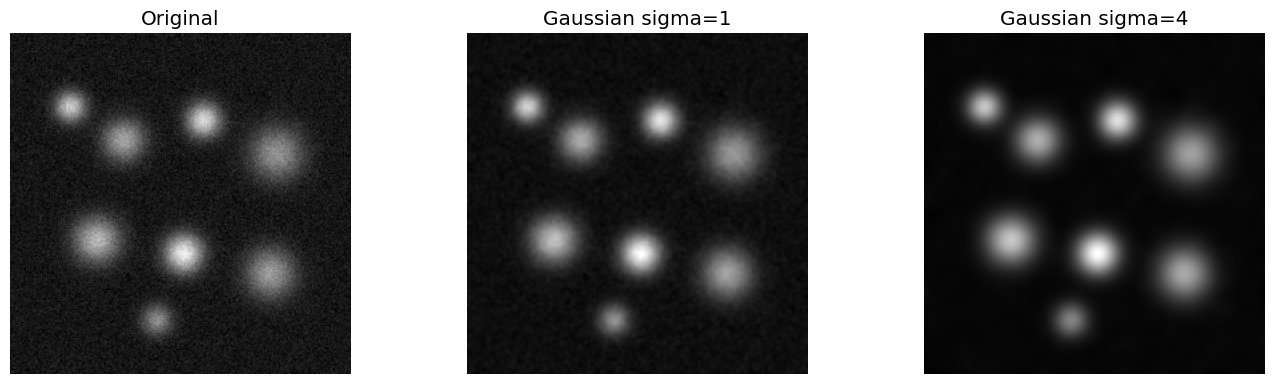

In [19]:
blur_1 = filters.gaussian(microscopy, sigma=1)
blur_4 = filters.gaussian(microscopy, sigma=4)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(microscopy, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(blur_1, cmap="gray")
axes[1].set_title("Gaussian sigma=1")

axes[2].imshow(blur_4, cmap="gray")
axes[2].set_title("Gaussian sigma=4")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Larger `sigma` means stronger smoothing. Filtering can improve segmentation, but excessive smoothing can merge nearby structures or erase small ones.

### Try it yourself

Apply Gaussian filters with `sigma=0.5`, `2`, and `6`. Compare the images or their standard deviations. What happens to fine detail as sigma increases?

In [20]:
# YOUR CODE HERE

### Edge detection

Edge filters emphasize rapid intensity changes rather than bright interiors.

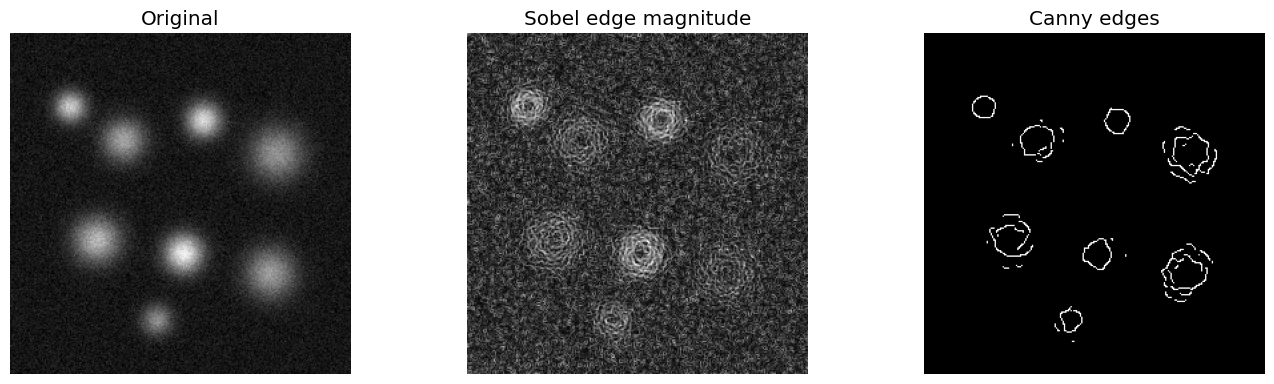

In [21]:
sobel_edges = filters.sobel(microscopy)
canny_edges = feature.canny(microscopy, sigma=2)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(microscopy, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(sobel_edges, cmap="gray")
axes[1].set_title("Sobel edge magnitude")

axes[2].imshow(canny_edges, cmap="gray")
axes[2].set_title("Canny edges")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Thresholding: from intensities to a binary mask

Thresholding asks a simple classification question for every pixel:

```text
Is this pixel above or below a chosen intensity?
```

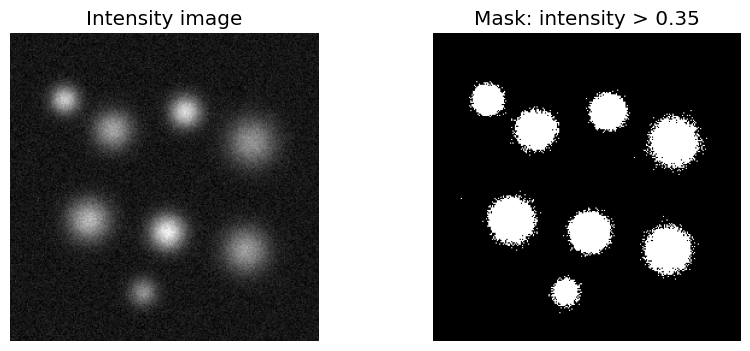

In [22]:
manual_threshold = 0.35
manual_mask = microscopy > manual_threshold

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(microscopy, cmap="gray")
axes[0].set_title("Intensity image")

axes[1].imshow(manual_mask, cmap="gray")
axes[1].set_title(f"Mask: intensity > {manual_threshold}")

for ax in axes:
    ax.axis("off")

plt.show()

Instead of selecting the threshold manually, algorithms such as **Otsu's method** estimate a threshold from the image histogram.

Otsu threshold: 0.3938467


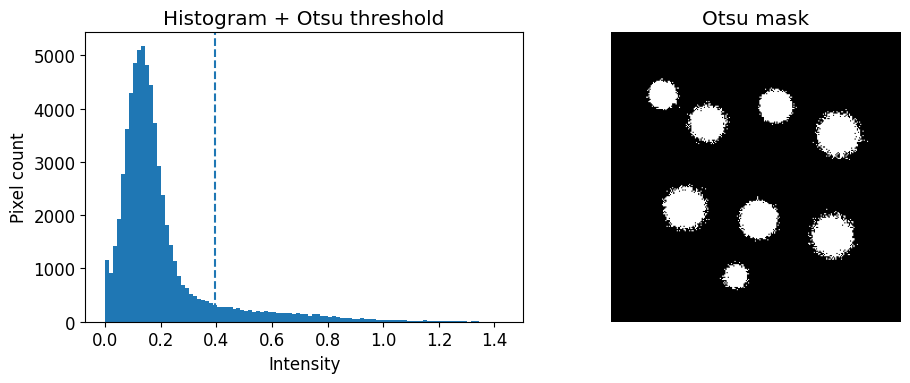

In [23]:
otsu_threshold = filters.threshold_otsu(microscopy)
otsu_mask = microscopy > otsu_threshold

print("Otsu threshold:", otsu_threshold)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(microscopy.ravel(), bins=100)
axes[0].axvline(otsu_threshold, linestyle="--")
axes[0].set_xlabel("Intensity")
axes[0].set_ylabel("Pixel count")
axes[0].set_title("Histogram + Otsu threshold")

axes[1].imshow(otsu_mask, cmap="gray")
axes[1].set_title("Otsu mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Try it yourself

Try thresholds `0.25`, `0.35`, and `0.50`. For each one, calculate the number or fraction of foreground pixels. How sensitive is the result to threshold choice?

In [24]:
# YOUR CODE HERE

## 11. Segmentation and morphological cleanup

A thresholded mask is often only the beginning of segmentation.

Common cleanup operations include:

- removing small objects,
- filling small holes,
- erosion and dilation,
- opening and closing.

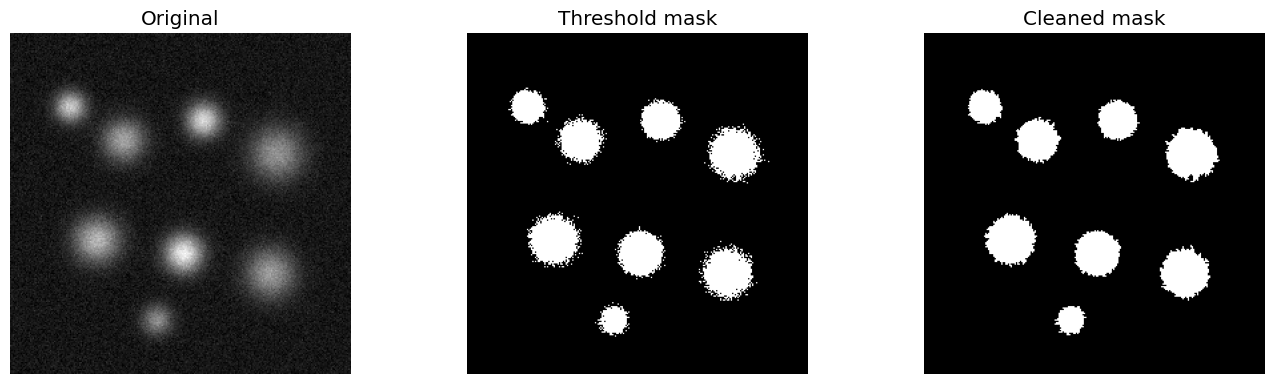

In [25]:
raw_mask = microscopy > otsu_threshold

clean_mask = morphology.remove_small_objects(raw_mask, min_size=80)
clean_mask = morphology.remove_small_holes(clean_mask, area_threshold=80)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(microscopy, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(raw_mask, cmap="gray")
axes[1].set_title("Threshold mask")

axes[2].imshow(clean_mask, cmap="gray")
axes[2].set_title("Cleaned mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 12. Connected components: turning foreground pixels into objects

A binary mask only says foreground/background. Connected-component labeling assigns a unique integer ID to each connected object.

In [26]:
labels = measure.label(clean_mask, connectivity=2)

print("Number of connected components:", labels.max())
print("Unique labels:", np.unique(labels))

Number of connected components: 8
Unique labels: [0 1 2 3 4 5 6 7 8]


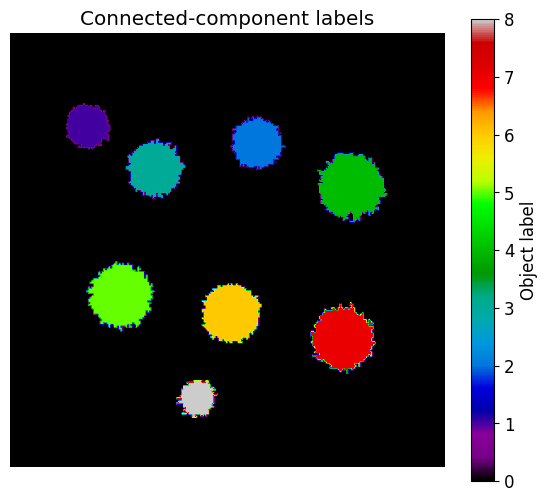

In [27]:
plt.figure(figsize=(7, 6))
plt.imshow(labels, cmap="nipy_spectral")
plt.colorbar(label="Object label")
plt.title("Connected-component labels")
plt.axis("off")
plt.show()

In a 2-D binary image:

- `connectivity=1` considers side-sharing neighbors connected.
- `connectivity=2` also allows diagonal connections.

The definition of connectivity can change the number of detected objects.

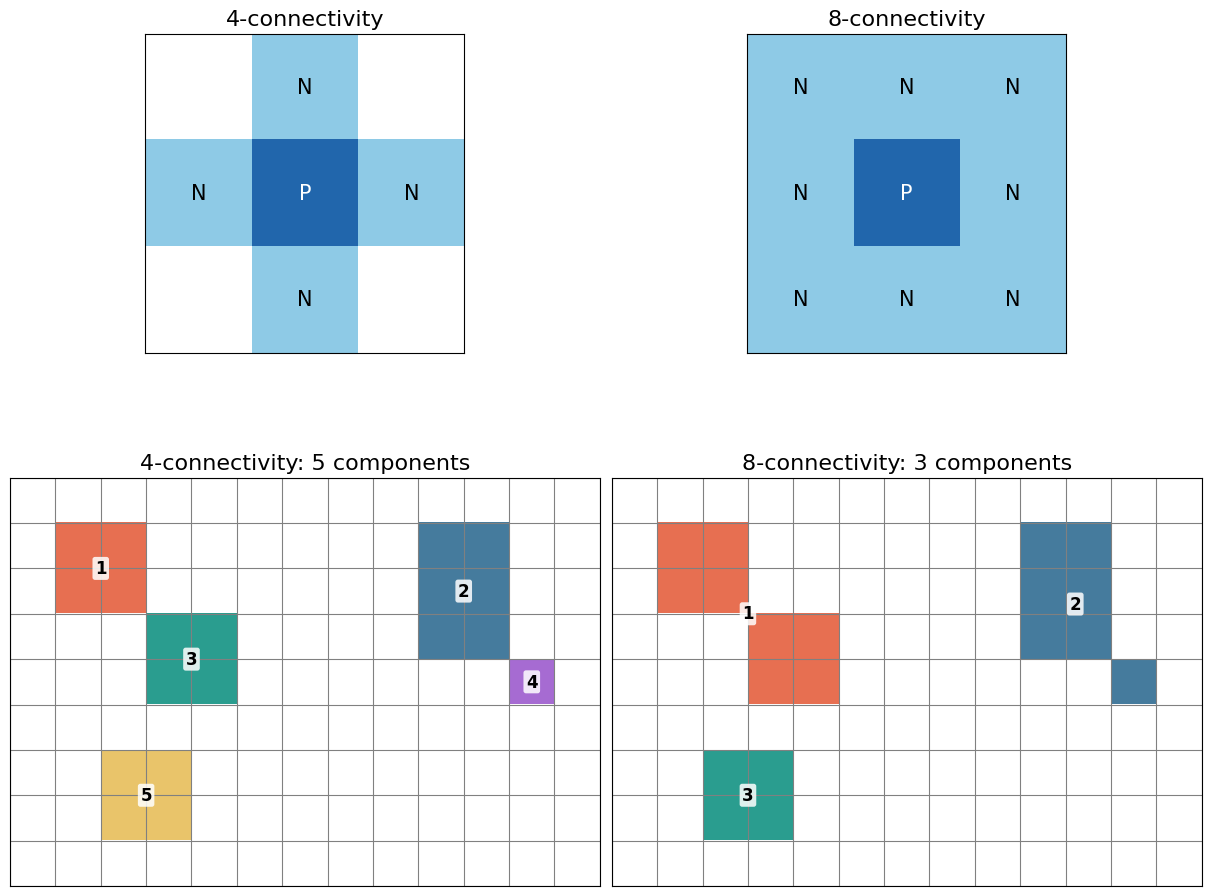

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage.measure import label

# Create an example binary image
mask = np.zeros((9, 13), dtype=bool)

# Two squares touching diagonally
mask[1:3, 1:3] = True
mask[3:5, 3:5] = True

# Another independent object
mask[6:8, 2:4] = True

# A larger object with one diagonally connected pixel
mask[1:4, 9:11] = True
mask[4, 11] = True

# Connected components
labels4 = label(mask, connectivity=1)
labels8 = label(mask, connectivity=2)

n4 = labels4.max()
n8 = labels8.max()

# Neighborhood diagrams (2 = center, 1 = neighbor)
neighbors4 = np.array([
    [0, 1, 0],
    [1, 2, 1],
    [0, 1, 0],
])

neighbors8 = np.array([
    [1, 1, 1],
    [1, 2, 1],
    [1, 1, 1],
])

neighbor_cmap = ListedColormap([
    "white", "#8ecae6", "#2166ac"
])

component_cmap = ListedColormap([
    "white",
    "#e76f51",
    "#457b9d",
    "#2a9d8f",
    "#a66bd2",
    "#e9c46a",
    "#e94f9e",
])

def draw_grid(ax, shape):
    h, w = shape
    ax.set_xticks(np.arange(-0.5, w, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, h, 1), minor=True)
    ax.grid(which="minor", color="gray", linewidth=0.8)
    ax.tick_params(
        which="both",
        bottom=False, left=False,
        labelbottom=False, labelleft=False
    )

def plot_neighbors(ax, neighbors, title):
    ax.imshow(neighbors, cmap=neighbor_cmap,
              vmin=0, vmax=2)
    draw_grid(ax, neighbors.shape)
    ax.set_title(title, fontsize=16)

    for y in range(3):
        for x in range(3):
            if neighbors[y, x] > 0:
                ax.text(
                    x, y,
                    "P" if neighbors[y, x] == 2 else "N",
                    ha="center", va="center",
                    fontsize=15,
                    color="white" if neighbors[y, x] == 2
                                  else "black"
                )

def plot_components(ax, labels, title):
    ax.imshow(labels, cmap=component_cmap,
              vmin=-0.5, vmax=6.5,
              interpolation="nearest")
    draw_grid(ax, labels.shape)
    ax.set_title(title, fontsize=16)

    # Annotate each connected component with its ID
    for k in range(1, labels.max() + 1):
        coords = np.argwhere(labels == k)
        cy, cx = coords.mean(axis=0)
        ax.text(
            cx, cy, str(k),
            ha="center", va="center",
            fontsize=12, fontweight="bold",
            bbox=dict(facecolor="white",
                      alpha=0.85, edgecolor="none",
                      boxstyle="round,pad=0.15")
        )

fig, ax = plt.subplots(
    2, 2, figsize=(12, 10),
    gridspec_kw={"height_ratios": [1, 2]},
    constrained_layout=True
)

plot_neighbors(ax[0, 0], neighbors4, "4-connectivity")
plot_neighbors(ax[0, 1], neighbors8, "8-connectivity")

plot_components(
    ax[1, 0], labels4,
    f"4-connectivity: {n4} components"
)
plot_components(
    ax[1, 1], labels8,
    f"8-connectivity: {n8} components"
)

plt.show()

## 13. Measure segmented objects

Once objects have labels, we can convert image information into a table.

In [29]:
props = measure.regionprops_table(
    labels,
    intensity_image=microscopy,
    properties=[
        "label",
        "area",
        "centroid",
        "mean_intensity",
        "max_intensity",
    ],
)

objects = pd.DataFrame(props)
objects

,label,area,centroid-0,centroid-1,mean_intensity,max_intensity
0,1,509.0,54.970530,45.302554,0.691842,1.214411
1,2,696.0,65.004310,144.972701,0.719596,1.277244
2,3,809.0,80.067985,84.838072,0.615735,0.979069
3,4,1146.0,90.249564,200.342932,0.579278,0.955692
4,5,1085.0,154.833180,64.765899,0.645891,1.105493
5,6,922.0,165.062907,129.654013,0.755167,1.430138
6,7,1052.0,179.785171,195.432510,0.598358,1.009501
7,8,351.0,215.022792,109.766382,0.561319,0.884961


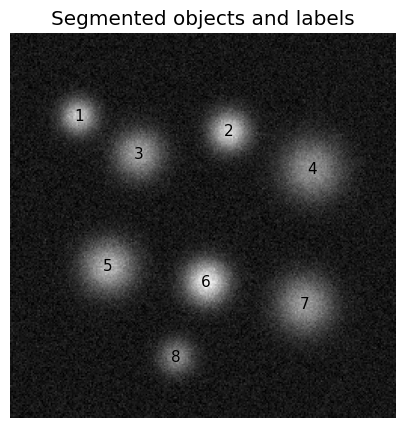

In [30]:
plt.figure(figsize=(7, 5))
plt.imshow(microscopy, cmap="gray")

for _, row in objects.iterrows():
    y0 = row["centroid-0"]
    x0 = row["centroid-1"]
    label_id = int(row["label"])

    plt.text(
        x0, y0, str(label_id),
        ha="center", va="center",
        fontsize=11
    )

plt.title("Segmented objects and labels")
plt.axis("off")
plt.show()

## 14. Registration: align images into the same coordinate system

Registration estimates a transformation that maps a moving image onto a reference image.

For teaching, it is useful to create a known shift and ask the algorithm to recover it.

In [31]:
reference = filters.gaussian(microscopy, sigma=1.5)

true_shift = (12.4, -8.7)  # (y, x)
moving = ndi.shift(reference, shift=true_shift, order=1, mode="constant")

recovered_shift, error, phasediff = registration.phase_cross_correlation(
    reference,
    moving,
    upsample_factor=20
)

registered = ndi.shift(
    moving,
    shift=recovered_shift,
    order=1,
    mode="constant"
)

print("Shift used to create moving image:", true_shift)
print("Shift estimated for correction   :", recovered_shift)
print("Registration error metric        :", error)

Shift used to create moving image: (12.4, -8.7)
Shift estimated for correction   : [-11.9   9. ]
Registration error metric        : 1.0


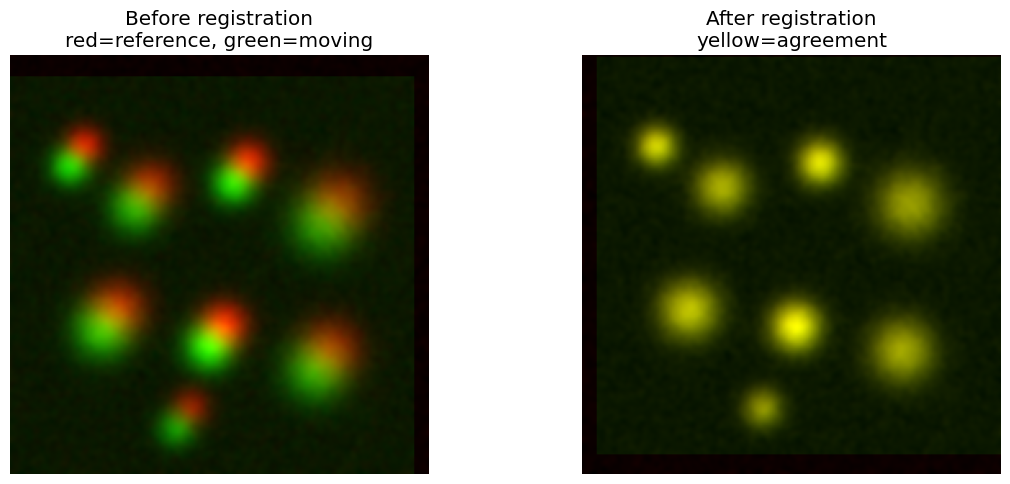

In [32]:
def red_green_overlay(a, b):
    a = exposure.rescale_intensity(a, out_range=(0, 1))
    b = exposure.rescale_intensity(b, out_range=(0, 1))

    rgb = np.zeros((*a.shape, 3), dtype=np.float32)
    rgb[..., 0] = a
    rgb[..., 1] = b
    return np.clip(rgb, 0, 1)

before = red_green_overlay(reference, moving)
after = red_green_overlay(reference, registered)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(before)
axes[0].set_title("Before registration\nred=reference, green=moving")

axes[1].imshow(after)
axes[1].set_title("After registration\nyellow=agreement")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

The estimated correction has approximately the opposite sign of the shift used to generate the moving image, because the algorithm estimates how to move the **moving** image back onto the reference.

### Try it yourself

Create a second moving image using a different translation. Estimate the correction. How close is the recovered value to the negative of the applied translation?

In [33]:
# YOUR CODE HERE

## 15. Time series

A time series can be represented as a stack of 2-D frames:

```text
T, Y, X
```

Let's create a bright object moving across the field of view.

In [34]:
T = 12
yy, xx = np.mgrid[:160, :220]
movie = []

for t in range(T):
    x0 = 30 + 13 * t
    y0 = 80 + 10 * np.sin(t / 2)

    frame = np.exp(
        -((xx - x0)**2 + (yy - y0)**2) / (2 * 10**2)
    )

    movie.append(frame)

movie = np.stack(movie)

print("Movie shape:", movie.shape)

Movie shape: (12, 160, 220)


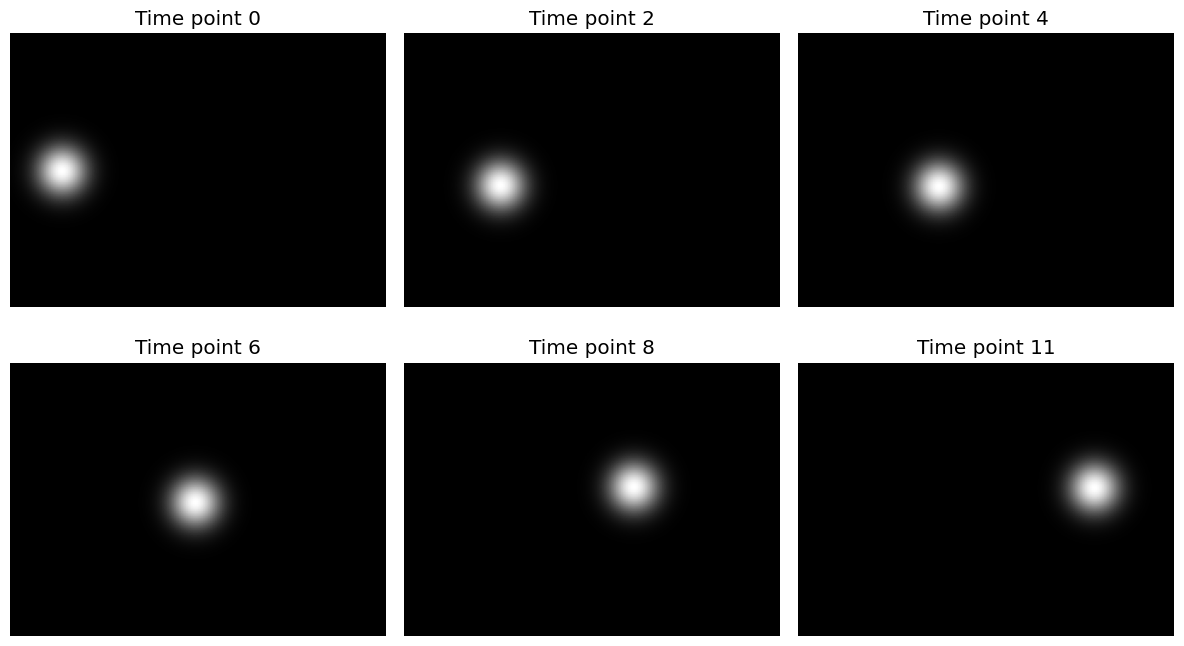

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, t in zip(axes.ravel(), [0, 2, 4, 6, 8, 11]):
    ax.imshow(movie[t], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Time point {t}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Optional interactive time slider

If `ipywidgets` is installed:

In [36]:
try:
    from ipywidgets import interact

    @interact(t=(0, len(movie) - 1))
    def show_time(t=0):
        plt.figure(figsize=(6, 4))
        plt.imshow(movie[t], cmap="gray", vmin=0, vmax=1)
        plt.title(f"Time point {t}")
        plt.axis("off")
        plt.show()

except ImportError:
    print("ipywidgets is not installed. This optional section can be skipped.")

interactive(children=(IntSlider(value=0, description='t', max=11), Output()), _dom_classes=('widget-interact',…

## 16. Mini capstone: image → mask → objects → measurements

A simple quantitative workflow often looks like:

```text
raw image
   ↓
preprocessing
   ↓
thresholding
   ↓
binary mask
   ↓
cleanup
   ↓
connected components
   ↓
measurements
   ↓
table / statistics
```

In [37]:
capstone_filtered = filters.gaussian(microscopy, sigma=1.5)

capstone_threshold = filters.threshold_otsu(capstone_filtered)

capstone_mask = capstone_filtered > capstone_threshold

capstone_mask = morphology.remove_small_objects(
    capstone_mask,
    min_size=100
)

capstone_labels = measure.label(capstone_mask)

capstone_table = pd.DataFrame(
    measure.regionprops_table(
        capstone_labels,
        intensity_image=microscopy,
        properties=[
            "label",
            "area",
            "centroid",
            "mean_intensity"
        ]
    )
)

print("Objects detected:", len(capstone_table))
capstone_table

Objects detected: 8


,label,area,centroid-0,centroid-1,mean_intensity
0,1,539.0,55.011132,45.256030,0.672011
1,2,727.0,64.938102,145.099037,0.703175
2,3,845.0,80.017751,85.044970,0.603584
3,4,1196.0,90.142977,200.020903,0.568958
4,5,1117.0,154.888988,64.852283,0.635881
5,6,954.0,165.063941,130.002096,0.740446
6,7,1104.0,179.943841,195.069746,0.585791
7,8,362.0,214.950276,109.895028,0.551483


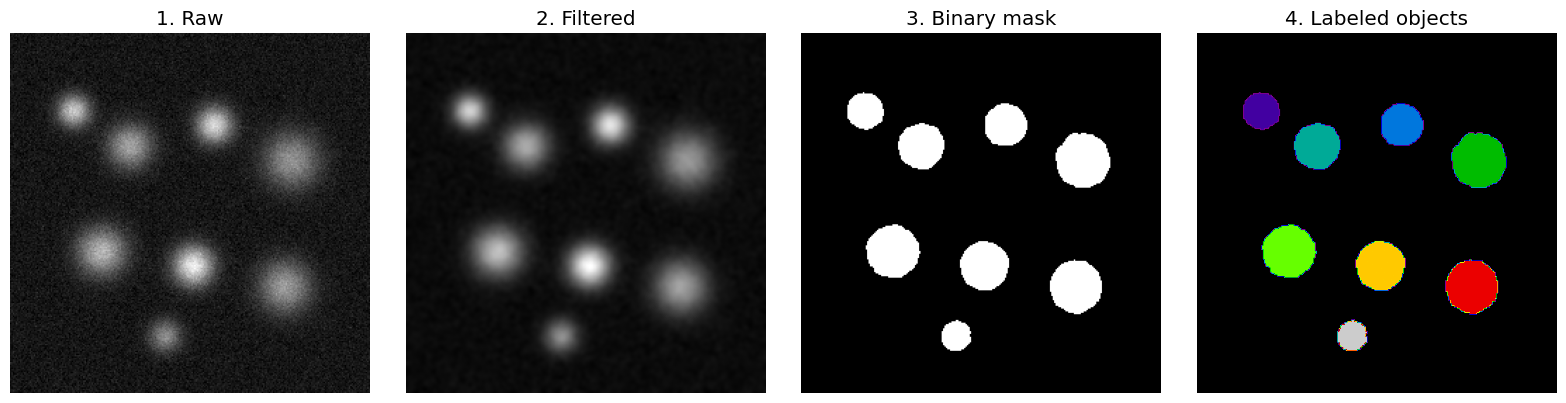

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(microscopy, cmap="gray")
axes[0].set_title("1. Raw")

axes[1].imshow(capstone_filtered, cmap="gray")
axes[1].set_title("2. Filtered")

axes[2].imshow(capstone_mask, cmap="gray")
axes[2].set_title("3. Binary mask")

axes[3].imshow(capstone_labels, cmap="nipy_spectral")
axes[3].set_title("4. Labeled objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Try it yourself

Write down which parameters in the capstone workflow should be recorded so that another researcher can reproduce the analysis.

In [39]:
# Write your answer as comments here.

## 17. Load a real TIFF image

Once the ideas above are clear, apply the same workflow to real microscopy data: two fluorescence channels of a brain slice, each stored as a single 16-bit TIFF plane (5107 × 4012 pixels).

The steps below mirror the mini-capstone from Section 16, now on real data:

- **17.1** Load the two channels
- **17.2** Adjust the display contrast manually (LUT limits)
- **17.3** Compare with automatic contrast limits
- **17.4** Display the green and red channels together
- **17.5** Register the red channel to the green channel
- **17.6** Apply the correction and display the aligned overlay
- **17.7** Segment the green channel by thresholding
- **17.8** Create the binary mask for the green channel
- **17.9** Segment the red channel
- **17.10** Improve thresholding: rolling-ball background subtraction
- **17.11** Repeat thresholding on the corrected image
- **17.12** Automate thresholding
- **17.13** Pixel-wise colocalization
- **17.14** Connected-component analysis
- **17.15** Measure morphological features with `regionprops`
- **17.16** Object-wise colocalization


### 17.1 Load the two channels

We load two TIFF files from the same acquisition of a brain slice:

- `r03_t00_c00_z0440.tif` — channel 0, which we will display in **green**
- `r03_t00_c01_z0440.tif` — channel 1, which we will display in **red**

The file names encode the acquisition dimensions, a common convention in microscopy:

- `r03` — region 3
- `t00` — time point 0
- `c00` / `c01` — channel 0 / channel 1
- `z0440` — Z-slice 440

Both files are therefore single 2-D planes: one region, one time point, one Z position, two different channels. After loading, recall from Sections 2 and 5 that you can inspect the arrays with `.shape`, `.dtype`, `np.min`, and `np.max` — the images are 16-bit, so values can range from 0 to 65535.


In [40]:
image_green = tifffile.imread("r03_t00_c00_z0440.tif")
image_red = tifffile.imread("r03_t00_c01_z0440.tif")

### 17.2 Adjust the display contrast manually (LUT limits)

Real fluorescence images are often dim, with only a small fraction of pixels carrying signal. Displaying them with the full data range — the matplotlib default — can make the sample look almost black.

The cell below shows the green channel two ways:

- **left** — the original display, using the full intensity range,
- **right** — the same data displayed with adjustable LUT limits (`vmin` / `vmax`).

Pixels darker than `vmin` are shown black, and pixels brighter than `vmax` are shown white. The slider is initialized from the 1st and 99.5th percentiles, a robust starting point when a few very bright pixels would otherwise flatten the rest of the image.

Use the slider to find limits that make the structures most informative. As in Section 4, this changes only the **display**, not the underlying pixel values.


In [41]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

# Image intensity range
data_min = float(np.min(image_green))
data_max = float(np.max(image_green))

# Initial contrast limits (percentile-based)
p_low, p_high = np.percentile(image_green, [1, 99.5])

# Handle images with very sparse signal
if p_high <= p_low:
    p_low, p_high = data_min, data_max

# Two-handle LUT slider
lut_slider = widgets.FloatRangeSlider(
    value=(float(p_low), float(p_high)),
    min=data_min,
    max=data_max,
    step=(data_max - data_min) / 1000,
    description="LUT limits:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="650px"),
)

def show_image(limits):
    vmin, vmax = limits

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Original image
    axes[0].imshow(image_green, cmap="gray")
    axes[0].set_title("Original display")

    # Image with adjustable LUT
    axes[1].imshow(
        image_green,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    axes[1].set_title(f"LUT: {vmin:.1f} - {vmax:.1f}")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

widgets.interact(show_image, limits=lut_slider);


interactive(children=(FloatRangeSlider(value=(3440.0, 12428.0), continuous_update=False, description='LUT limi…

### 17.3 Compare with automatic contrast limits

Instead of choosing limits by eye, contrast can be stretched automatically. The cell below compares three panels:

- **left** — the original image, displayed with its full data range,
- **middle** — the image after `skimage.exposure.rescale_intensity` maps the 1st–98th percentile range onto the full data-type range,
- **right** — your manual LUT choice from the slider.

Note the key distinction from Section 3: the automatic rescaling **changes pixel values** (it re-maps intensities), whereas the manual LUT limits only change how the same values are displayed. Compare your limits with the automatic ones: both should make the same structures visible.


In [42]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from skimage import exposure

# Image intensity statistics
data_min = float(np.min(image_green))
data_max = float(np.max(image_green))

# Calculate percentiles for automatic contrast stretching
p_low, p_high = np.percentile(image_green, [1, 98])

# Automatically rescale intensities
image_rescaled = exposure.rescale_intensity(
    image_green,
    in_range=(p_low, p_high),
    out_range="dtype"
)

# Full display range of the image dtype
if np.issubdtype(image_green.dtype, np.integer):
    dtype_info = np.iinfo(image_green.dtype)
    full_min, full_max = dtype_info.min, dtype_info.max
else:
    full_min, full_max = 0.0, 1.0  # normalized float images

# Interactive slider for manual LUT adjustment
lut_slider = widgets.FloatRangeSlider(
    value=(float(p_low), float(p_high)),
    min=data_min,
    max=data_max,
    step=(data_max - data_min) / 1000,
    description="LUT limits:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="650px")
)

def show_comparison(limits):
    vmin, vmax = limits

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # 1. Original image
    axes[0].imshow(
        image_green, cmap="gray",
        vmin=full_min, vmax=full_max
    )
    axes[0].set_title("Original image")

    # 2. Automatically rescaled image
    axes[1].imshow(
        image_rescaled, cmap="gray",
        vmin=full_min, vmax=full_max
    )
    axes[1].set_title("Automatic rescale_intensity 1-98%")

    # 3. Manual LUT adjustment
    axes[2].imshow(
        image_green, cmap="gray",
        vmin=vmin, vmax=vmax
    )
    axes[2].set_title(f"Manual LUT: {vmin:.1f} - {vmax:.1f}")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

widgets.interact(show_comparison, limits=lut_slider);


interactive(children=(FloatRangeSlider(value=(3440.0, 7481.0), continuous_update=False, description='LUT limit…

### 17.4 Display the green and red channels together

Fluorescence channels are commonly compared by overlaying them as a color composite: the green channel fills the green plane of an RGB image, the red channel fills the red plane, and pixels where both channels are bright appear **yellow**.

To mimic a real registration problem, the red image is first shifted with `np.roll`:

```text
image_red_shifted = np.roll(image_red, shift=(-40, 80), axis=(0, 1))
```

**Observe:** if you adjust the two LUT sliders, you will notice that the red channel is shifted with respect to the green channel — structures that should coincide appear as separate red and green fringes instead of yellow. This is exactly the problem that registration (Section 14) solves, and we fix it in the next steps.


In [43]:
import numpy as np
import ipywidgets as widgets
from IPython.display import display

# Display helper: map intensities from a (vmin, vmax) LUT range to [0, 1]
def apply_lut(image, limits):
    vmin, vmax = limits
    image = image.astype(np.float32)
    if vmax <= vmin:
        vmax = vmin + 1
    return np.clip((image - vmin) / (vmax - vmin), 0, 1)

# Two-handle LUT slider initialized from robust percentiles
def make_lut_slider(image, description):
    data_min = float(np.min(image))
    data_max = float(np.max(image))
    p_low, p_high = np.percentile(image, [1, 99.5])
    if p_high <= p_low:
        p_low, p_high = data_min, data_max
    return widgets.FloatRangeSlider(
        value=(float(p_low), float(p_high)),
        min=data_min,
        max=data_max,
        step=(data_max - data_min) / 1000,
        description=description,
        continuous_update=False,
        readout_format=".1f",
        layout=widgets.Layout(width="650px"),
    )

# One LUT slider per channel
green_slider = make_lut_slider(image_green, "Green LUT:")
red_slider = make_lut_slider(image_red, "Red LUT:")


In [44]:
import numpy as np

image_red_shifted = np.roll(
    image_red,
    shift=(-40, 80),
    axis=(0, 1)
)

def show_overlay(green_limits, red_limits):

    green = apply_lut(image_green, green_limits)
    red = apply_lut(image_red_shifted, red_limits)

    # Combine channels into an RGB image
    rgb = np.zeros((*green.shape, 3), dtype=np.float32)
    rgb[..., 0] = red      # R
    rgb[..., 1] = green    # G
    rgb[..., 2] = 0        # B

    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(rgb)
    ax.set_title("Red + Green overlay", fontsize=15)
    ax.axis("off")
    plt.show()

output = widgets.interactive_output(
    show_overlay,
    {
        "green_limits": green_slider,
        "red_limits": red_slider
    }
)

display(widgets.VBox([green_slider, red_slider]), output)

Output()

### 17.5 Register the red channel to the green channel

We now estimate the translation that maps the shifted red image back onto the green image:

- the **green** image is the *reference* and stays fixed,
- the shifted **red** image is the *moving* image.

`skimage.registration.phase_cross_correlation` compares the Fourier transforms of the two images and returns the translation that best aligns them; with `upsample_factor=20` the estimate has sub-pixel precision. As in Section 14, the estimated correction moves the **moving** image back onto the reference, so its sign is approximately the opposite of the shift that was applied.


In [45]:
# Red image is the moving image
moving = image_red_shifted

# Green image is the reference
reference = image_green

# Estimate the translation
recovered_shift, error, phasediff = registration.phase_cross_correlation(
    reference,
    moving,
    upsample_factor=20
)

print("Estimated correction (y, x):", recovered_shift)

Estimated correction (y, x): [ 39.9 -80.1]


### 17.6 Apply the correction and display the aligned overlay

The estimated translation is applied to the red image with `scipy.ndimage.shift`. Bilinear interpolation (`order=1`) fills in non-integer sample positions, and `mode="grid-wrap"` handles values that shift in from beyond the border.

Run the cell and compare the overlay with the uncorrected one from 17.4: structures that appeared as separate red and green fringes should now largely coincide as yellow.


In [46]:
# Apply the estimated correction to the original red image
registered_red = ndi.shift(
    image_red_shifted,
    shift=recovered_shift,
    order=1,
    mode="grid-wrap"
)

def show_overlay(green_limits, red_limits):

    green = apply_lut(image_green, green_limits)
    red = apply_lut(registered_red, red_limits)

    # Combine channels into an RGB image
    rgb = np.zeros((*green.shape, 3), dtype=np.float32)
    rgb[..., 0] = red      # R
    rgb[..., 1] = green    # G
    rgb[..., 2] = 0        # B

    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(rgb)
    ax.set_title("Red + Green overlay", fontsize=15)
    ax.axis("off")
    plt.show()

output = widgets.interactive_output(
    show_overlay,
    {
        "green_limits": green_slider,
        "red_limits": red_slider
    }
)

display(widgets.VBox([green_slider, red_slider]), output)

Output()

### 17.7 Segment the green channel by thresholding

We now segment the green channel using the approach from Section 10. The cell below provides three sliders:

- **LUT** — display limits for the grayscale image (display only),
- **Threshold** — the intensity above which a pixel counts as foreground,
- **Mask alpha** — transparency of the red mask overlay.

The threshold is always applied to the **raw** image data, independent of the LUT choice. The printed feedback reports how many pixels, and what fraction of the image, lie above the threshold.

Use the sliders to choose a threshold that captures the labeled structures while excluding the background, and note the value you settle on for the next cell.


In [47]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Choose the image to segment
image = image_green   # or image_red, or any 2D grayscale image

# Basic checks
assert image.ndim == 2, "This example expects a 2D grayscale image."

data_min = float(np.min(image))
data_max = float(np.max(image))

# Initial LUT limits from percentiles
lut_low, lut_high = np.percentile(image, [1, 99.5])
if lut_high <= lut_low:
    lut_low, lut_high = data_min, data_max

# Initial threshold (you can change this choice)
thr_init = float(np.percentile(image, 95))

# LUT slider
lut_slider = widgets.FloatRangeSlider(
    value=(float(lut_low), float(lut_high)),
    min=data_min,
    max=data_max,
    step=max((data_max - data_min) / 1000, 1e-6),
    description="LUT:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="650px"),
)

# Threshold slider
threshold_slider = widgets.FloatSlider(
    value=thr_init,
    min=data_min,
    max=data_max,
    step=max((data_max - data_min) / 1000, 1e-6),
    description="Threshold:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="650px"),
)

# Opacity slider for the mask overlay (optional, but useful)
alpha_slider = widgets.FloatSlider(
    value=0.35,
    min=0.0,
    max=1.0,
    step=0.05,
    description="Mask alpha:",
    continuous_update=False,
    readout_format=".2f",
    layout=widgets.Layout(width="650px"),
)

def show_thresholding(lut_limits, threshold, mask_alpha):
    vmin, vmax = lut_limits

    # Threshold is applied to the raw image data
    mask = image >= threshold

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Left: original image with chosen LUT
    axes[0].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    axes[0].set_title("Original image")
    axes[0].axis("off")

    # Right: original image + mask overlay
    axes[1].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    axes[1].imshow(mask, cmap="Reds", alpha=mask_alpha, interpolation="none")
    axes[1].set_title(f"Thresholded mask overlay (threshold = {threshold:.1f})")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    # Useful quantitative feedback for students
    n_pixels = mask.sum()
    frac = 100 * n_pixels / mask.size
    print(f"Pixels above threshold: {n_pixels} / {mask.size} ({frac:.2f}%)")

output = widgets.interactive_output(
    show_thresholding,
    {
        "lut_limits": lut_slider,
        "threshold": threshold_slider,
        "mask_alpha": alpha_slider,
    }
)

display(widgets.VBox([lut_slider, threshold_slider, alpha_slider]), output)

Output()

In [48]:
### Input your value here
threshold = 5011

### 17.8 Create the binary mask for the green channel

The comparison `image_green > threshold` classifies every pixel and returns a **boolean mask**: `True` for foreground, `False` for background. A mask contains no intensity information — only the segmentation decision (Section 10).

Run the cell and compare the displayed mask with the interactive overlay from 17.7: they should agree.


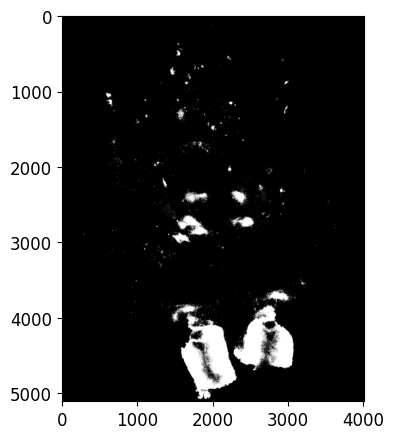

In [49]:
mask_green = image_green > threshold
plt.imshow(mask_green, cmap="grey")

### 17.9 Segment the red channel

The same thresholding procedure is now applied to the red channel, with the same interactive sliders.

Real red channels often carry more uneven background and autofluorescence than the green channel, so a single global threshold may be a poor fit here — which motivates the background-correction step in 17.10.


In [50]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Choose the image to segment
image = image_red

# Basic checks
assert image.ndim == 2, "This example expects a 2D grayscale image."

data_min = float(np.min(image))
data_max = float(np.max(image))

# Initial LUT limits from percentiles
lut_low, lut_high = np.percentile(image, [1, 99.5])
if lut_high <= lut_low:
    lut_low, lut_high = data_min, data_max

# Initial threshold (you can change this choice)
thr_init = float(np.percentile(image, 95))

# LUT slider
lut_slider = widgets.FloatRangeSlider(
    value=(float(lut_low), float(lut_high)),
    min=data_min,
    max=data_max,
    step=max((data_max - data_min) / 1000, 1e-6),
    description="LUT:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="650px"),
)

# Threshold slider
threshold_slider = widgets.FloatSlider(
    value=thr_init,
    min=data_min,
    max=data_max,
    step=max((data_max - data_min) / 1000, 1e-6),
    description="Threshold:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="650px"),
)

# Opacity slider for the mask overlay (optional, but useful)
alpha_slider = widgets.FloatSlider(
    value=0.35,
    min=0.0,
    max=1.0,
    step=0.05,
    description="Mask alpha:",
    continuous_update=False,
    readout_format=".2f",
    layout=widgets.Layout(width="650px"),
)

def show_thresholding(lut_limits, threshold, mask_alpha):
    vmin, vmax = lut_limits

    # Threshold is applied to the raw image data
    mask = image >= threshold

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Left: original image with chosen LUT
    axes[0].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    axes[0].set_title("Original image")
    axes[0].axis("off")

    # Right: original image + mask overlay
    axes[1].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    axes[1].imshow(mask, cmap="Reds", alpha=mask_alpha, interpolation="none")
    axes[1].set_title(f"Thresholded mask overlay (threshold = {threshold:.1f})")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    # Useful quantitative feedback for students
    n_pixels = mask.sum()
    frac = 100 * n_pixels / mask.size
    print(f"Pixels above threshold: {n_pixels} / {mask.size} ({frac:.2f}%)")

output = widgets.interactive_output(
    show_thresholding,
    {
        "lut_limits": lut_slider,
        "threshold": threshold_slider,
        "mask_alpha": alpha_slider,
    }
)

display(widgets.VBox([lut_slider, threshold_slider, alpha_slider]), output)

Output()

### 17.10 Improve thresholding: rolling-ball background subtraction

A common preprocessing step before thresholding is to remove a slowly varying background. The **rolling-ball** algorithm (as in ImageJ) slides a ball of a given diameter along the underside of the intensity surface; the ball cannot enter narrow peaks, so it traces the smooth background beneath them. Subtracting this background leaves the signal on a flat baseline.

The cell below shows three panels:

- **original** fluorescence,
- the **estimated background** traced by the ball,
- the **background-subtracted** image, `max(raw − background, 0)`.

The corrected image and the estimated background are stored in the `results` dictionary for use in later cells. Try different ball diameters (the slider ranges from 10 to 100 px, default 40): a small ball follows more structure and removes more signal, while a large ball leaves more background. Choose a diameter that flattens the background while preserving the labeled structures.


In [51]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
import io

from functools import lru_cache
from skimage.restoration import rolling_ball
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

# Enable widgets in Google Colab
try:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
except ImportError:
    pass

# -------------------------------------------------------
# INPUT IMAGE
# -------------------------------------------------------

image = np.asarray(image_red, dtype=np.float32)

if image.ndim != 2:
    raise ValueError("Please provide a 2D grayscale image.")

# Use a smaller ROI for faster interactive processing.
# Set to None to process the entire image.
PREVIEW_SIZE = None   # 320

if PREVIEW_SIZE is not None:
    h, w = image.shape
    y0 = max(0, (h - PREVIEW_SIZE) // 2)
    x0 = max(0, (w - PREVIEW_SIZE) // 2)
    image = image[y0:y0 + PREVIEW_SIZE,
                  x0:x0 + PREVIEW_SIZE]

# Linear normalization to 0-255
raw_min = float(image.min())
raw_range = max(float(image.max() - raw_min), 1e-10)
raw = (image - raw_min) * (255.0 / raw_range)

green_cmap = LinearSegmentedColormap.from_list(
    "fluorescence", ["black", "lime"]
)

# -------------------------------------------------------
# ROLLING-BALL BACKGROUND
# -------------------------------------------------------

@lru_cache(maxsize=10)
def get_background(diameter):
    return rolling_ball(raw, radius=diameter / 2.0)

# -------------------------------------------------------
# WIDGETS
# -------------------------------------------------------

lut_lo = int(np.percentile(raw, 1))
lut_hi = min(
    255,
    max(lut_lo + 1, int(np.percentile(raw, 99.5)))
)

lut_slider = widgets.IntRangeSlider(
    value=(lut_lo, lut_hi),
    min=0,
    max=255,
    step=1,
    description="Original LUT:",
    continuous_update=False,
    layout=widgets.Layout(width="550px"),
    style={"description_width": "150px"}
)

diameter_slider = widgets.IntSlider(
    value=40,
    min=10,
    max=100,
    step=10,
    description="Ball diameter (px):",
    continuous_update=False,
    layout=widgets.Layout(width="550px"),
    style={"description_width": "150px"}
)

image_widget = widgets.Image(format="png")

# -------------------------------------------------------
# DISPLAY CONTRAST
# -------------------------------------------------------

def auto_lut(arr, low=1, high=99.8):
    vmin = float(np.percentile(arr, low))
    vmax = float(np.percentile(arr, high))

    if vmax <= vmin:
        vmax = vmin + 1

    return vmin, vmax

# -------------------------------------------------------
# UPDATE FUNCTION
# -------------------------------------------------------

results = {}

def update(change=None):

    diameter = diameter_slider.value
    raw_vmin, raw_vmax = lut_slider.value

    if raw_vmax <= raw_vmin:
        raw_vmax = raw_vmin + 1

    # Rolling-ball background correction
    background = get_background(diameter)
    corrected = np.maximum(raw - background, 0)
    
    # Save the latest results for use in other notebook cells
    results["corrected"] = corrected
    results["background"] = background
    results["diameter"] = diameter
    
    # Independent display LUTs
    bg_vmin, bg_vmax = auto_lut(background)
    corr_vmin, corr_vmax = auto_lut(corrected)

    # Create three-panel figure
    with plt.ioff():
        fig, ax = plt.subplots(
            1, 3,
            figsize=(13, 4.5),
            constrained_layout=True
        )

    # Original
    ax[0].imshow(
        raw,
        cmap=green_cmap,
        vmin=raw_vmin,
        vmax=raw_vmax
    )
    ax[0].set_title("Original fluorescence")

    # Estimated background
    ax[1].imshow(
        background,
        cmap=green_cmap,
        vmin=bg_vmin,
        vmax=bg_vmax
    )
    ax[1].set_title("Estimated background")

    # Background-subtracted
    ax[2].imshow(
        corrected,
        cmap=green_cmap,
        vmin=corr_vmin,
        vmax=corr_vmax
    )
    ax[2].set_title("Background-subtracted")

    for a in ax:
        a.axis("off")

    fig.suptitle(
        f"Rolling-ball diameter: {diameter} px",
        fontsize=14
    )

    # Render figure to PNG
    buf = io.BytesIO()
    fig.savefig(
        buf,
        format="png",
        dpi=90,
        facecolor=fig.get_facecolor()
    )

    plt.close(fig)

    image_widget.value = buf.getvalue()
    buf.close()

# -------------------------------------------------------
# CONNECT WIDGETS
# -------------------------------------------------------

lut_slider.observe(update, names="value")
diameter_slider.observe(update, names="value")

display(widgets.VBox([
    lut_slider,
    diameter_slider,
    image_widget
]))

update()


### 17.11 Repeat thresholding on the corrected image

Now threshold the background-corrected image stored in `results["corrected"]` (from 17.10), using the same interactive sliders.

Compare the threshold value and the resulting mask with the uncorrected red channel from 17.9: background correction usually allows a lower, more reliable threshold, because the background baseline is now flat.


In [52]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Choose the image to segment
image = results["corrected"]

# Basic checks
assert image.ndim == 2, "This example expects a 2D grayscale image."

data_min = float(np.min(image))
data_max = float(np.max(image))

# Initial LUT limits from percentiles
lut_low, lut_high = np.percentile(image, [1, 99.5])
if lut_high <= lut_low:
    lut_low, lut_high = data_min, data_max

# Initial threshold (you can change this choice)
thr_init = float(np.percentile(image, 95))

# LUT slider
lut_slider = widgets.FloatRangeSlider(
    value=(float(lut_low), float(lut_high)),
    min=data_min,
    max=data_max,
    step=max((data_max - data_min) / 1000, 1e-6),
    description="LUT:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="650px"),
)

# Threshold slider
threshold_slider = widgets.FloatSlider(
    value=thr_init,
    min=data_min,
    max=data_max,
    step=max((data_max - data_min) / 1000, 1e-6),
    description="Threshold:",
    continuous_update=False,
    readout_format=".1f",
    layout=widgets.Layout(width="650px"),
)

# Opacity slider for the mask overlay (optional, but useful)
alpha_slider = widgets.FloatSlider(
    value=0.35,
    min=0.0,
    max=1.0,
    step=0.05,
    description="Mask alpha:",
    continuous_update=False,
    readout_format=".2f",
    layout=widgets.Layout(width="650px"),
)

def show_thresholding(lut_limits, threshold, mask_alpha):
    vmin, vmax = lut_limits

    # Threshold is applied to the raw image data
    mask = image >= threshold

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Left: original image with chosen LUT
    axes[0].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    axes[0].set_title("Original image")
    axes[0].axis("off")

    # Right: original image + mask overlay
    axes[1].imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    axes[1].imshow(mask, cmap="Reds", alpha=mask_alpha, interpolation="none")
    axes[1].set_title(f"Thresholded mask overlay (threshold = {threshold:.1f})")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    # Useful quantitative feedback for students
    n_pixels = mask.sum()
    frac = 100 * n_pixels / mask.size
    print(f"Pixels above threshold: {n_pixels} / {mask.size} ({frac:.2f}%)")

output = widgets.interactive_output(
    show_thresholding,
    {
        "lut_limits": lut_slider,
        "threshold": threshold_slider,
        "mask_alpha": alpha_slider,
    }
)

display(widgets.VBox([lut_slider, threshold_slider, alpha_slider]), output)

Output()

### 17.12 Automate thresholding

Manual thresholds are subjective and hard to reproduce. **Otsu's method** (Section 10) estimates thresholds directly from the intensity histogram, making the segmentation automatic and reproducible.

The next three cells:

1. inspect the intensity histogram on linear and logarithmic scales,
2. overlay Otsu thresholds for 2–5 classes on the histogram,
3. compare the resulting segmentation interactively.

Because real fluorescence histograms are rarely a clean two-peak mixture, the interactive cell uses **multi-Otsu** to pick two thresholds from the histogram — the first separating background from foreground, the last separating the brightest signal — which you can also adjust by hand.


First, let's look at the intensity histogram. The logarithmic y-scale makes the small signal populations visible.


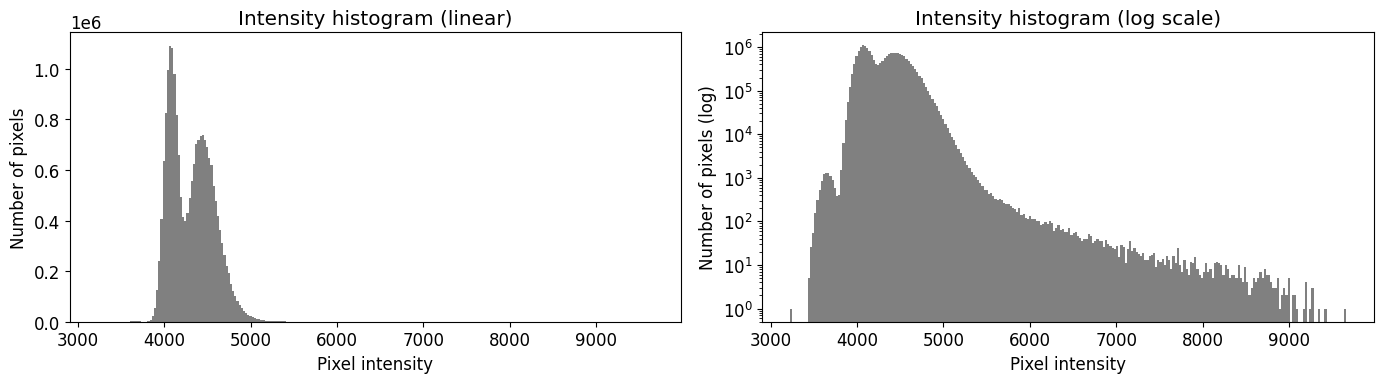

In [53]:
image = image_red

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Linear histogram
axes[0].hist(image.ravel(), bins=256, color="gray")
axes[0].set_title("Intensity histogram (linear)")
axes[0].set_xlabel("Pixel intensity")
axes[0].set_ylabel("Number of pixels")

# Logarithmic histogram
axes[1].hist(image.ravel(), bins=256, color="gray", log=True)
axes[1].set_title("Intensity histogram (log scale)")
axes[1].set_xlabel("Pixel intensity")
axes[1].set_ylabel("Number of pixels (log)")

plt.tight_layout()
plt.show()

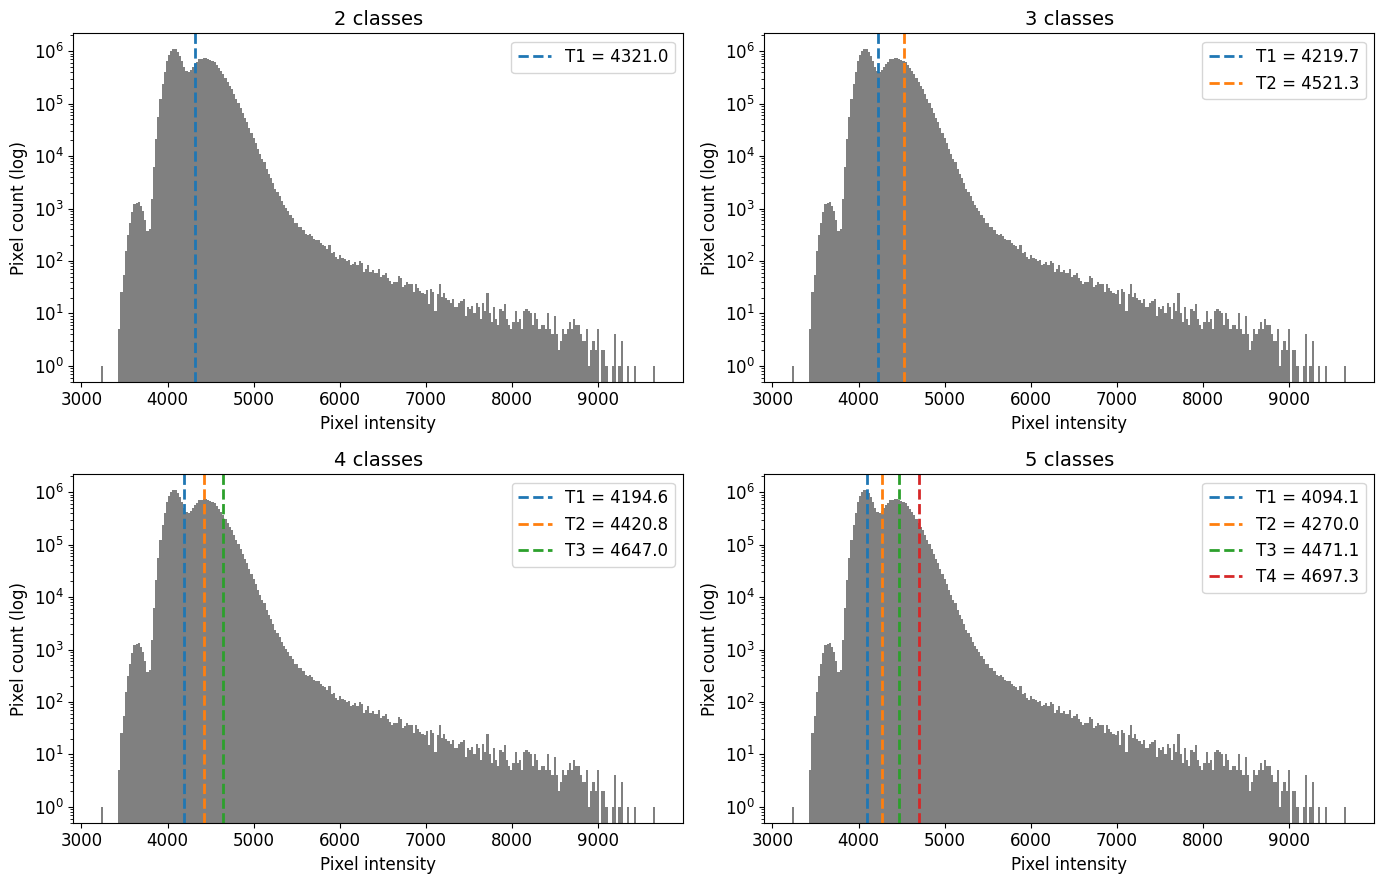

In [54]:
from skimage import filters

image = image_red

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, n_classes in zip(axes.flat, [2, 3, 4, 5]):

    # Calculate Otsu thresholds
    if n_classes == 2:
        thresholds = [filters.threshold_otsu(image)]
    else:
        thresholds = filters.threshold_multiotsu(
            image.astype(np.float32),
            classes=n_classes,
            nbins=256
        )

    # Plot histogram
    ax.hist(
        image.ravel(),
        bins=256,
        color="gray",
        log=True
    )

    # Draw each threshold
    for i, threshold in enumerate(thresholds):
        ax.axvline(
            threshold,
            color=f"C{i}",
            linestyle="--",
            linewidth=2,
            label=f"T{i+1} = {threshold:.1f}"
        )

    ax.set_title(f"{n_classes} classes", fontsize=14)
    ax.set_xlabel("Pixel intensity")
    ax.set_ylabel("Pixel count (log)")
    ax.legend()

plt.tight_layout()
plt.show()


In [55]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from skimage import filters
from IPython.display import display
from matplotlib.colors import ListedColormap

# ==========================================================
# 1. Select the image
# ==========================================================

image = np.asarray(image_red)

assert image.ndim == 2, "Image must be 2D"
assert np.isfinite(image).all(), "Image contains NaN or Inf"

data_min = float(image.min())
data_max = float(image.max())

if data_min == data_max:
    raise ValueError("Image has constant intensity")

# Float conversion ensures the requested histogram bin count
# is used even for uint16 images.
image_float = image.astype(np.float32, copy=False)

# ==========================================================
# 2. Calculate thresholds using both methods
# ==========================================================

# Method A: Multi-Otsu, 3 classes, 2 thresholds
multi_thresholds = tuple(map(
    float,
    filters.threshold_multiotsu(
        image_float, classes=5, nbins=256
    )
))

# Method B: Hierarchical (sequential) Otsu
# First separate foreground from background
t1 = float(filters.threshold_otsu(image_float))

# Then separate bright signal within the foreground
foreground = image_float[image_float >= t1]

if foreground.min() == foreground.max():
    raise ValueError(
        "Foreground has insufficient intensity variation "
        "for a second Otsu threshold."
    )

t2 = float(filters.threshold_otsu(foreground))

# sequential_thresholds = (t1, t2)

# if t2 <= t1:
#     raise ValueError(
#         "Hierarchical Otsu did not produce two ordered thresholds."
#     )

# print("Multi-Otsu thresholds:", multi_thresholds)
# print("Hierarchical Otsu thresholds:", sequential_thresholds)

# ==========================================================
# 3. Create widgets
# ==========================================================

method_dropdown = widgets.Dropdown(
    options=[
        ("Multi-Otsu (3 classes)", "multi"),
        ("Hierarchical Otsu (2 steps)", "sequential"),
    ],
    value="multi",
    description="Method:",
    layout=widgets.Layout(width="400px")
)

# LUT limits
lut_low, lut_high = np.percentile(image, [1, 99.5])

if lut_low >= lut_high:
    lut_low, lut_high = data_min, data_max

step = max((data_max - data_min) / 1000, 1e-6)
fmt = ".3f" if data_max <= 2 else ".1f"

lut_slider = widgets.FloatRangeSlider(
    value=(float(lut_low), float(lut_high)),
    min=data_min,
    max=data_max,
    step=step,
    description="LUT:",
    continuous_update=False,
    readout_format=fmt,
    layout=widgets.Layout(width="650px")
)

# Two threshold handles
threshold_slider = widgets.FloatRangeSlider(
    value=(multi_thresholds[0], multi_thresholds[-1]),
    min=data_min,
    max=data_max,
    step=step,
    description="T1 / T2:",
    continuous_update=False,
    readout_format=fmt,
    layout=widgets.Layout(width="650px")
)

# Overlay transparency
alpha_slider = widgets.FloatSlider(
    value=0.40,
    min=0,
    max=1,
    step=0.05,
    description="Opacity:",
    continuous_update=False,
    layout=widgets.Layout(width="650px")
)

# Automatically calculated thresholds
automatic_thresholds = {
    "multi": multi_thresholds,
    # "sequential": sequential_thresholds,
}

# ==========================================================
# 4. Visualization function
# ==========================================================

def show_segmentation(method, lut_limits, thresholds, opacity):

    vmin, vmax = lut_limits
    t1, t4 = thresholds

    # Binary masks calculated from ORIGINAL pixel values
    foreground_mask = image >= t1
    bright_mask = image >= t4

    # Masked overlays (only True pixels are colored)
    foreground_overlay = np.ma.masked_where(
        ~foreground_mask, foreground_mask
    )
    bright_overlay = np.ma.masked_where(
        ~bright_mask, bright_mask
    )

    fig, axes = plt.subplots(
        1, 3, figsize=(17, 5)
    )

    # All panels use the same grayscale LUT
    for ax in axes:
        ax.imshow(
            image,
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )
        ax.axis("off")

    # Panel 1: Original image
    axes[0].set_title(
        "Original image",
        fontsize=15
    )

    # Panel 2: Foreground in cyan
    axes[1].imshow(
        foreground_overlay,
        cmap=ListedColormap(["cyan"]),
        alpha=opacity,
        interpolation="nearest"
    )
    axes[1].set_title(
        f"Foreground (T1 = {t1:.2f})",
        fontsize=15
    )

    # Panel 3: Bright fluorescence in red
    axes[2].imshow(
        bright_overlay,
        cmap=ListedColormap(["red"]),
        alpha=opacity,
        interpolation="nearest"
    )
    axes[2].set_title(
        f"Bright fluorescence (T2 = {t2:.2f})",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

    # Quantitative feedback
    print(f"Method: {method}")
    print(f"Threshold 1: {t1:.3f}")
    print(f"Threshold 2: {t2:.3f}")
    print(f"Foreground: {foreground_mask.mean()*100:.2f}% of pixels")
    print(f"Bright signal: {bright_mask.mean()*100:.2f}% of pixels")

# ==========================================================
# 5. Switch methods and reset thresholds
# ==========================================================

def reset_thresholds(button=None):
    threshold_slider.value = automatic_thresholds[
        method_dropdown.value
    ]

def on_method_change(change):
    reset_thresholds()

method_dropdown.observe(on_method_change, names="value")

reset_button = widgets.Button(
    description="Reset to automatic thresholds",
    button_style="info"
)

reset_button.on_click(reset_thresholds)

# ==========================================================
# 6. Connect everything
# ==========================================================

output = widgets.interactive_output(
    show_segmentation,
    {
        "method": method_dropdown,
        "lut_limits": lut_slider,
        "thresholds": threshold_slider,
        "opacity": alpha_slider,
    }
)

display(
    widgets.VBox([
        method_dropdown,
        lut_slider,
        threshold_slider,
        alpha_slider,
        reset_button
    ]),
    output
)


Output()

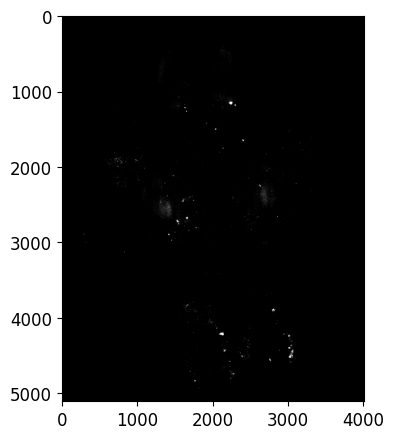

In [56]:
### Insert your value
threshold = 5144

mask_red = image_red > threshold
plt.imshow(mask_red, cmap="grey")

### 17.13 Pixel-wise colocalization

Colocalization asks how much of the signal in the two channels occupies the same pixels. Using the binary masks created above (`mask_green` from 17.8, `mask_red` from 17.12), the cell below computes three regions:

- `green_only = mask_green & ~mask_red`
- `red_only = mask_red & ~mask_green`
- `overlap = mask_green & mask_red`

and from them reports standard metrics:

- the **fraction of green overlapping red**, and vice versa,
- the **Jaccard index** (intersection over union),
- the **Dice coefficient**.

The middle panel shows the thresholded channels with their overlap in yellow; the right panel marks overlapping pixels in white. The display uses the registered red channel from 17.6.


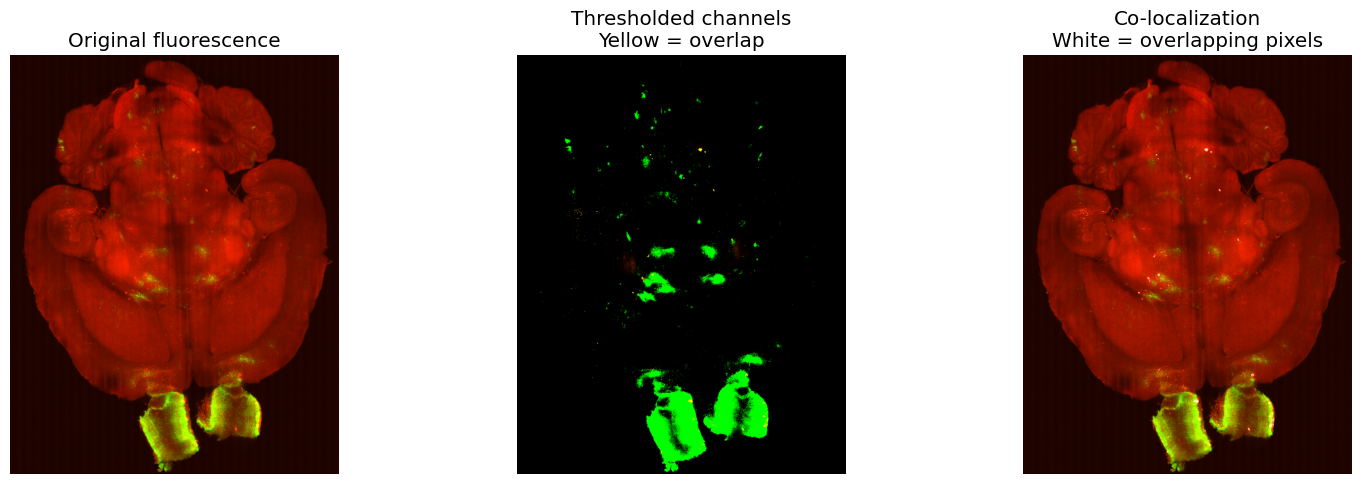

Green-positive pixels: 1,023,897
Red-positive pixels:   36,495
Overlapping pixels:    18,109

Green signal overlapping red: 1.8%
Red signal overlapping green: 49.6%
Jaccard index: 0.017
Dice coefficient: 0.034


In [57]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters

# ----------------------------------------------------
# 1. Threshold both channels
# ----------------------------------------------------

# Done above

# ----------------------------------------------------
# 2. Calculate co-localization
# ----------------------------------------------------

green_only = mask_green & ~mask_red
red_only = mask_red & ~mask_green
overlap = mask_green & mask_red

# ----------------------------------------------------
# 3. Calculate co-localization metrics
# ----------------------------------------------------

n_green = np.count_nonzero(mask_green)
n_red = np.count_nonzero(mask_red)
n_overlap = np.count_nonzero(overlap)
n_union = np.count_nonzero(mask_green | mask_red)

# Fraction of each channel overlapping the other
fraction_green = n_overlap / n_green if n_green else np.nan
fraction_red = n_overlap / n_red if n_red else np.nan

# Intersection over Union (Jaccard index)
jaccard = n_overlap / n_union if n_union else np.nan

# Dice coefficient
dice = (
    2 * n_overlap / (n_green + n_red)
    if n_green + n_red else np.nan
)

# ----------------------------------------------------
# 4. Prepare the original RGB image for display
# ----------------------------------------------------

def normalize_display(image):
    p1, p99 = np.percentile(image, [1, 99.5])
    if p99 <= p1:
        return np.zeros(image.shape, dtype=np.float32)

    image = image.astype(np.float32)
    return np.clip((image - p1) / (p99 - p1), 0, 1)

rgb = np.zeros((*image_green.shape, 3), dtype=np.float32)
rgb[..., 0] = normalize_display(registered_red)
rgb[..., 1] = normalize_display(image_green)

# Color-coded binary masks:
# Red only = red
# Green only = green
# Both = yellow
seg_rgb = np.zeros_like(rgb)
seg_rgb[..., 0] = mask_red.astype(float)
seg_rgb[..., 1] = mask_green.astype(float)

# White transparent overlay marking overlapping pixels
overlap_overlay = np.zeros((*overlap.shape, 4), dtype=np.float32)
overlap_overlay[..., :3] = 1.0
overlap_overlay[..., 3] = overlap.astype(float) * 0.8

# ----------------------------------------------------
# 5. Visualize results
# ----------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original fluorescence")

axes[1].imshow(seg_rgb)
axes[1].set_title("Thresholded channels\nYellow = overlap")

axes[2].imshow(rgb)
axes[2].imshow(overlap_overlay)
axes[2].set_title("Co-localization\nWhite = overlapping pixels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# 6. Print quantitative results
# ----------------------------------------------------

print(f"Green-positive pixels: {n_green:,}")
print(f"Red-positive pixels:   {n_red:,}")
print(f"Overlapping pixels:    {n_overlap:,}")

print(f"\nGreen signal overlapping red: {fraction_green:.1%}")
print(f"Red signal overlapping green: {fraction_red:.1%}")
print(f"Jaccard index: {jaccard:.3f}")
print(f"Dice coefficient: {dice:.3f}")


### 17.14 Connected-component analysis

A binary mask says only foreground/background. As in Section 12, connected-component labeling with `measure.label` (`connectivity=2`, i.e. 8-connected in 2-D) turns each connected group of foreground pixels into an object with a unique integer ID.

The cells below:

1. label both channels and report the object counts,
2. define `label_and_filter`, which removes components smaller than `min_area` pixels and relabels the rest consecutively,
3. let you tune `min_area` interactively.

Sweep the **min area** slider and watch the object counts: small specks of noise disappear, while real structures survive.


Green channel: 15482 objects
Red channel:   12727 objects


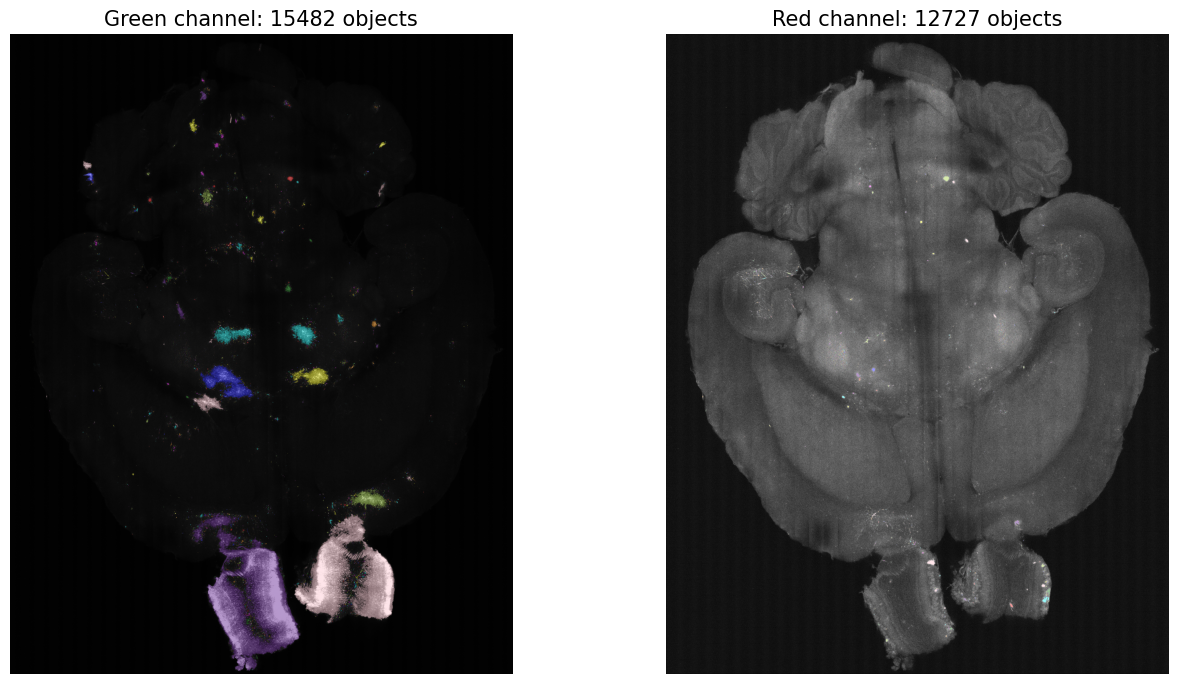

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import measure, color

# --------------------------------------------------
# 1. Label connected components
# --------------------------------------------------

# connectivity=2 means 8-connected pixels in 2D
labels_green = measure.label(mask_green, connectivity=2)
labels_red = measure.label(mask_red, connectivity=2)

print(f"Green channel: {labels_green.max()} objects")
print(f"Red channel:   {labels_red.max()} objects")


# --------------------------------------------------
# 2. Normalize image intensity for visualization
# --------------------------------------------------

def normalize_display(image):
    p1, p99 = np.percentile(image, [1, 99.5])

    if p99 <= p1:
        return np.zeros(image.shape, dtype=np.float32)

    image = image.astype(np.float32)
    return np.clip((image - p1) / (p99 - p1), 0, 1)


# --------------------------------------------------
# 3. Overlay labels onto original images
# --------------------------------------------------

overlay_green = color.label2rgb(
    labels_green,
    image=normalize_display(image_green),
    alpha=0.4,
    bg_label=0,
    kind="overlay"
)

overlay_red = color.label2rgb(
    labels_red,
    image=normalize_display(registered_red),
    alpha=0.4,
    bg_label=0,
    kind="overlay"
)


# --------------------------------------------------
# 4. Visualize
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(overlay_green)
axes[0].set_title(
    f"Green channel: {labels_green.max()} objects",
    fontsize=15
)

axes[1].imshow(overlay_red)
axes[1].set_title(
    f"Red channel: {labels_red.max()} objects",
    fontsize=15
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [59]:
def label_and_filter(mask, min_area=20):
    # Identify all connected components
    labels = measure.label(mask, connectivity=2)

    # Count pixels in every labeled component
    areas = np.bincount(labels.ravel())

    # Keep only components above minimum area
    keep = areas >= min_area
    keep[0] = False  # Exclude background

    filtered_mask = keep[labels]

    # Relabel components consecutively
    return measure.label(filtered_mask, connectivity=2)


labels_green = label_and_filter(mask_green, min_area=20)
labels_red = label_and_filter(mask_red, min_area=20)

In [60]:
import ipywidgets as widgets

def show_components(min_area):
    labels_g = label_and_filter(mask_green, min_area)
    labels_r = label_and_filter(mask_red, min_area)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    for ax, image, labels, name in zip(
        axes,
        [image_green, registered_red],
        [labels_g, labels_r],
        ["Green", "Red"]
    ):
        overlay = color.label2rgb(
            labels,
            image=normalize_display(image),
            alpha=0.4,
            bg_label=0
        )

        ax.imshow(overlay)
        ax.set_title(
            f"{name}: {labels.max()} objects",
            fontsize=15
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()


widgets.interact(
    show_components,
    min_area=widgets.IntSlider(
        value=20,
        min=1,
        max=500,
        step=1,
        description="Min area:",
        continuous_update=False,
        layout=widgets.Layout(width="600px")
    )
);


interactive(children=(IntSlider(value=20, continuous_update=False, description='Min area:', layout=Layout(widt…

### 17.15 Measure morphological features with `regionprops`

Once objects have labels, `measure.regionprops_table` converts the segmentation into a table of per-object measurements (Section 13). The properties measured here include:

- **area** — number of pixels in the object,
- **centroid** — the object's center position (y, x),
- **perimeter**, **eccentricity**, **solidity**, **extent** — shape descriptors,
- **major/minor axis length**, **equivalent diameter** — size descriptors.

The tables are sorted by area, largest first, for both channels; the histogram that follows compares the object-size distributions between the green and red channels.


In [61]:

import pandas as pd
from skimage import measure
from IPython.display import display

# 10 measurements (centroid contributes 2 columns)
properties = [
    "label",
    "area",
    "centroid",
    "perimeter",
    "eccentricity",
    "solidity",
    "extent",
    "axis_major_length",
    "axis_minor_length",
    "equivalent_diameter_area",
]

def make_regionprops_table(labels):
    # Extract properties
    df = pd.DataFrame(
        measure.regionprops_table(
            labels,
            properties=properties
        )
    )

    # Rename columns for readability
    df = df.rename(columns={
        "label": "Object ID",
        "area": "Area (px²)",
        "centroid-0": "Centroid Y",
        "centroid-1": "Centroid X",
        "perimeter": "Perimeter (px)",
        "eccentricity": "Eccentricity",
        "solidity": "Solidity",
        "extent": "Extent",
        "axis_major_length": "Major axis (px)",
        "axis_minor_length": "Minor axis (px)",
        "equivalent_diameter_area": "Equivalent diameter (px)"
    })

    # Sort largest to smallest
    df = df.sort_values(
        "Area (px²)", ascending=False
    ).reset_index(drop=True)

    return df


# Generate tables for both channels
df_green = make_regionprops_table(labels_green)
df_red = make_regionprops_table(labels_red)

# Display largest 20 objects from each channel
print(f"GREEN CHANNEL: {len(df_green)} objects")
display(df_green.head(20).round(2))

print(f"\nRED CHANNEL: {len(df_red)} objects")
display(df_red.head(20).round(2))


GREEN CHANNEL: 674 objects


,Object ID,Area (px²),Centroid Y,Centroid X,Perimeter (px),Eccentricity,Solidity,Extent,Major axis (px),Minor axis (px),Equivalent diameter (px)
0,426,435264.0,4509.31,1923.78,44302.57,0.82,0.64,0.40,1169.14,672.42,744.44
1,437,338372.0,4330.15,2701.42,35744.23,0.25,0.70,0.48,821.03,794.13,656.38
2,264,47110.0,2779.63,1728.52,8982.40,0.89,0.64,0.41,420.89,195.80,244.91
3,369,22253.0,3713.18,2866.91,4678.36,0.90,0.63,0.46,275.17,120.91,168.33
4,270,21069.0,2731.20,2419.37,4518.23,0.90,0.63,0.51,283.70,121.83,163.79
5,202,18493.0,2397.27,1763.25,6736.18,0.94,0.57,0.44,314.10,106.52,153.45
6,197,17185.0,2394.05,2344.55,3798.43,0.77,0.71,0.48,195.30,124.54,147.92
7,310,15745.0,2944.82,1576.87,2777.16,0.85,0.65,0.41,210.36,111.70,141.59
8,56,4593.0,1297.45,1572.84,2076.42,0.66,0.56,0.39,105.67,79.03,76.47
9,18,3073.0,735.04,1460.50,882.79,0.84,0.64,0.44,95.12,52.23,62.55



RED CHANNEL: 127 objects


,Object ID,Area (px²),Centroid Y,Centroid X,Perimeter (px),Eccentricity,Solidity,Extent,Major axis (px),Minor axis (px),Equivalent diameter (px)
0,92,1567.0,4216.71,2116.36,321.18,0.79,0.77,0.55,60.70,36.89,44.67
1,3,1332.0,1152.93,2235.59,268.83,0.50,0.77,0.56,45.65,39.40,41.18
2,114,1180.0,4512.82,3027.91,489.72,0.82,0.59,0.43,61.97,35.60,38.76
3,79,655.0,3899.13,2798.33,229.03,0.40,0.59,0.40,36.99,33.84,28.88
4,62,554.0,2721.24,1530.74,241.69,0.84,0.63,0.40,39.83,21.83,26.56
5,107,547.0,4447.63,3052.71,310.97,0.88,0.56,0.36,48.75,23.46,26.39
6,61,495.0,2678.35,1655.29,174.79,0.35,0.74,0.53,27.34,25.61,25.10
7,104,429.0,4401.61,3009.81,124.85,0.59,0.80,0.57,26.88,21.67,23.37
8,96,369.0,4241.92,3005.84,141.02,0.37,0.68,0.49,25.35,23.56,21.68
9,119,353.0,4559.58,2754.63,129.85,0.91,0.71,0.42,34.82,14.63,21.20


### 17.16 Object-wise colocalization

Pixel-wise colocalization says nothing about individual objects. Here, overlap is evaluated **per object**: for every labeled object in each channel we count

- how many of its pixels overlap the other channel,
- what percentage of its area that represents,
- how many distinct partner objects it touches.

An object is flagged `Colocalized` when at least `min_pixels = 5` of its pixels overlap **and** at least `min_fraction = 0.20` (20 %) of its area overlaps. The two channels are evaluated independently, and the pairs table lists every overlapping green–red object pair.

The final cells highlight the co-localized objects on the composite image. Compare these object-based results with the pixel-wise metrics from 17.13: they answer related but different questions.


In [62]:
import numpy as np
import pandas as pd
from IPython.display import display

def object_colocalization(
    labels_green,
    labels_red,
    min_fraction=0.20,
    min_pixels=5,
):
    """
    Analyze object-wise overlap between two labeled images.

    An object is considered co-localized when:
      1. At least min_pixels of its pixels overlap
      2. At least min_fraction of its area overlaps

    The two channels are evaluated independently.
    Background label 0 is ignored.

    Returns:
        green_df, red_df, pairs_df
    """

    if labels_green.shape != labels_red.shape:
        raise ValueError("Images must have the same shape")

    ng = int(labels_green.max())
    nr = int(labels_red.max())

    # Area of each object (number of pixels)
    area_g = np.bincount(
        labels_green.ravel(), minlength=ng + 1
    )
    area_r = np.bincount(
        labels_red.ravel(), minlength=nr + 1
    )

    # Pixels belonging to objects in both channels
    shared = (labels_green > 0) & (labels_red > 0)

    # Overlapping pixels for every object
    overlap_g = np.bincount(
        labels_green[shared], minlength=ng + 1
    )
    overlap_r = np.bincount(
        labels_red[shared], minlength=nr + 1
    )

    # Identify every overlapping green/red object pair
    # Encode the label pair into a single integer
    packed = (
        labels_green[shared].astype(np.int64) * (nr + 1)
        + labels_red[shared]
    )

    keys, counts = np.unique(packed, return_counts=True)

    gids = keys // (nr + 1)
    rids = keys % (nr + 1)

    # Table of all intersecting object pairs
    pairs_df = pd.DataFrame({
        "Green ID": gids,
        "Red ID": rids,
        "Overlap (px)": counts,
        "% Green covered": 100 * counts / area_g[gids],
        "% Red covered": 100 * counts / area_r[rids],
    })

    pairs_df = pairs_df.sort_values(
        "Overlap (px)", ascending=False
    ).reset_index(drop=True)

    # Number of distinct overlapping partners
    partners_g = np.bincount(gids, minlength=ng + 1)
    partners_r = np.bincount(rids, minlength=nr + 1)

    # Create per-object tables
    def make_table(areas, overlaps, partners):
        ids = np.arange(1, len(areas))

        df = pd.DataFrame({
            "Object ID": ids,
            "Area (px)": areas[1:],
            "Overlap (px)": overlaps[1:],
            "Overlap (%)": (
                100 * overlaps[1:] / areas[1:]
            ),
            "Partner objects": partners[1:],
        })

        df["Colocalized"] = (
            (df["Overlap (px)"] >= min_pixels)
            & (df["Overlap (%)"] >= 100 * min_fraction)
        )

        return df.sort_values(
            "Area (px)", ascending=False
        ).reset_index(drop=True)

    green_df = make_table(area_g, overlap_g, partners_g)
    red_df = make_table(area_r, overlap_r, partners_r)

    return green_df, red_df, pairs_df


# --------------------------------------------------
# Run the analysis
# --------------------------------------------------

green_coloc, red_coloc, pairs_coloc = object_colocalization(
    labels_green,
    labels_red,
    min_fraction=0.20,
    min_pixels=5
)

print("GREEN OBJECTS")
display(green_coloc.head(20).round(2))

print("RED OBJECTS")
display(red_coloc.head(20).round(2))

print("OVERLAPPING RED-GREEN PAIRS")
display(pairs_coloc.head(20).round(2))


GREEN OBJECTS


,Object ID,Area (px),Overlap (px),Overlap (%),Partner objects,Colocalized
0,426,435264,3126,0.72,23,False
1,437,338372,4570,1.35,26,False
2,264,47110,1185,2.52,8,False
3,369,22253,0,0.00,0,False
4,270,21069,0,0.00,0,False
5,202,18493,143,0.77,3,False
6,197,17185,29,0.17,1,False
7,310,15745,0,0.00,0,False
8,56,4593,0,0.00,0,False
9,18,3073,0,0.00,0,False


RED OBJECTS


,Object ID,Area (px),Overlap (px),Overlap (%),Partner objects,Colocalized
0,92,1567,1563,99.74,1,True
1,3,1332,1169,87.76,1,True
2,114,1180,1180,100.00,1,True
3,79,655,641,97.86,1,True
4,62,554,401,72.38,2,True
5,107,547,546,99.82,1,True
6,61,495,495,100.00,1,True
7,104,429,429,100.00,1,True
8,96,369,369,100.00,1,True
9,119,353,353,100.00,1,True


OVERLAPPING RED-GREEN PAIRS


,Green ID,Red ID,Overlap (px),% Green covered,% Red covered
0,426,92,1563,0.36,99.74
1,437,114,1180,0.35,100.00
2,43,3,1169,91.61,87.76
3,437,79,641,0.19,97.86
4,437,107,546,0.16,99.82
5,264,61,495,1.05,100.00
6,437,104,429,0.13,100.00
7,264,62,399,0.85,72.02
8,437,96,369,0.11,100.00
9,437,119,353,0.10,100.00


In [63]:

def print_colocalization_summary(green_df, red_df):

    n_green = len(green_df)
    n_red = len(red_df)

    coloc_green = int(green_df["Colocalized"].sum())
    coloc_red = int(red_df["Colocalized"].sum())

    print("OBJECT-WISE CO-LOCALIZATION SUMMARY")
    print("-----------------------------------")

    print(f"Green objects: {n_green}")
    print(f"Red objects:   {n_red}")

    print(
        f"\nGreen objects co-localized with red: "
        f"{coloc_green}/{n_green} "
        f"({100 * coloc_green / n_green:.1f}%)"
        if n_green else "\nNo green objects detected"
    )

    print(
        f"Red objects co-localized with green: "
        f"{coloc_red}/{n_red} "
        f"({100 * coloc_red / n_red:.1f}%)"
        if n_red else "\nNo red objects detected"
    )


print_colocalization_summary(green_coloc, red_coloc)


OBJECT-WISE CO-LOCALIZATION SUMMARY
-----------------------------------
Green objects: 674
Red objects:   127

Green objects co-localized with red: 35/674 (5.2%)
Red objects co-localized with green: 99/127 (78.0%)


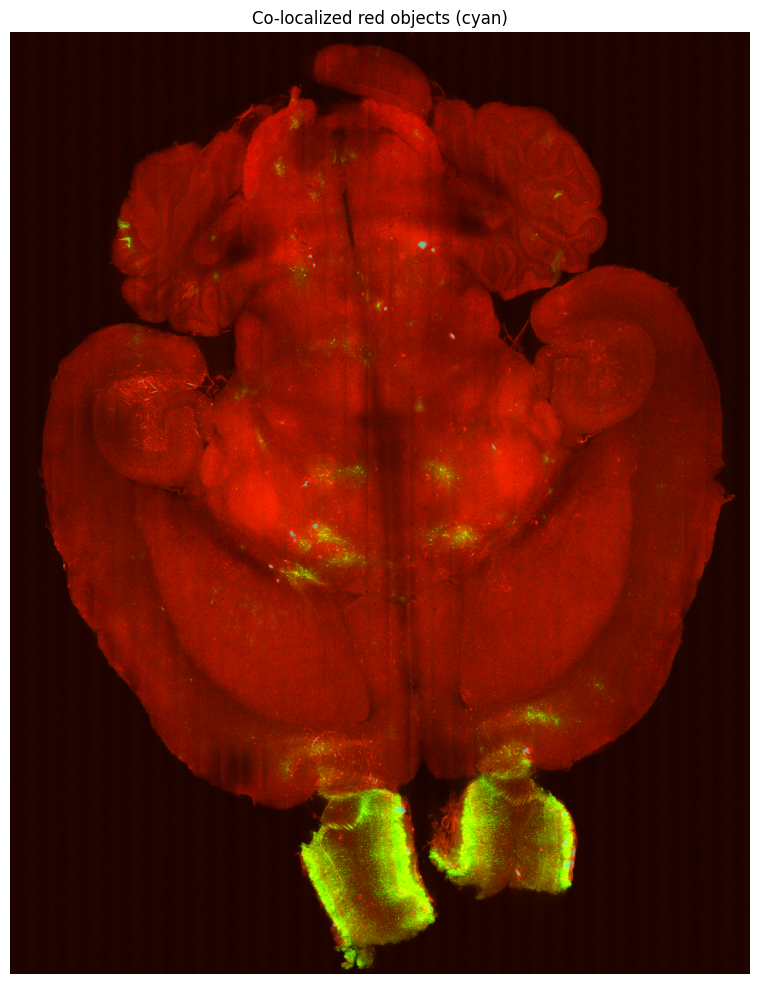

In [64]:
import matplotlib.pyplot as plt
import numpy as np

# Create RGB composite using the original intensities
rgb = np.zeros((*image_green.shape, 3), dtype=np.float32)
rgb[..., 0] = normalize_display(registered_red)
rgb[..., 1] = normalize_display(image_green)

# IDs of objects classified as co-localized
red_ids = red_coloc.loc[
    red_coloc["Colocalized"], "Object ID"
].to_numpy()

green_ids = green_coloc.loc[
    green_coloc["Colocalized"], "Object ID"
].to_numpy()

# Masks of entire co-localized objects
matched_red = np.isin(labels_red, red_ids)
matched_green = np.isin(labels_green, green_ids)

# Helper to make transparent overlays
def make_overlay(mask, color, alpha=0.55):
    overlay = np.zeros((*mask.shape, 4), dtype=np.float32)
    overlay[..., :3] = color
    overlay[..., 3] = mask.astype(float) * alpha
    return overlay

# Create overlays
overlay_red = make_overlay(matched_red, (0, 1, 1))      # cyan
overlay_green = make_overlay(matched_green, (1, 0, 1))  # magenta

# Plot only the 2 requested panels
fig, axes = plt.subplots(1, 1, figsize=(10, 10))

axes.imshow(rgb)
axes.imshow(overlay_red)
axes.set_title("Co-localized red objects (cyan)", fontsize=12)
axes.axis("off")

plt.tight_layout()
plt.show()

## Takeaway: good image-analysis habits

1. **Keep raw data unchanged.**
2. **Separate display operations from data-processing operations.**
3. **Record pixel size and other calibration metadata.**
4. **Know the array dimension order.**
5. **Record processing parameters.**
6. **Inspect intermediate results, not just the final numbers.**
7. **Use masks and overlays to validate segmentation visually.**
8. **Avoid interpreting display colors as intrinsic properties of the data.**
9. **Watch for saturation and clipping.**
10. **Save code and software versions for reproducibility.**

## Concept check

Discuss these questions:

1. If you change a grayscale image to a green LUT, have the pixel values changed?
2. Is a 16-bit image always more informative than an 8-bit image?
3. Is pixel size the same thing as optical resolution?
4. What is the difference between a binary mask and a labeled image?
5. Why can Gaussian filtering improve segmentation?
6. Why can too much Gaussian filtering be harmful?
7. What does a thresholding operation do?
8. Why does the connectivity definition matter?
9. What does registration change: intensities, spatial coordinates, or both?
10. Which steps in an image-analysis workflow should be reproducible?

---
## Advanced topics to look into

After this notebook, natural next lessons include:

- 3-D image stacks and maximum-intensity projections
- local/adaptive thresholding
- watershed segmentation
- background subtraction
- deconvolution
- colocalization
- object tracking
- 3-D connected components
- image metadata and OME-TIFF / OME-Zarr
- segmentation quality metrics
- machine-learning and deep-learning segmentation